In [631]:
import pandas as pd

In [632]:
df = pd.read_excel(
    '../data/Кейс_Ретейл и маркетинг_Дополнительные данные.xlsb',
    sheet_name=0,
    header=2,
    engine='calamine'
)

info = pd.read_excel(
    '../data/Кейс_Ретейл и маркетинг_Дополнительные данные.xlsb',
    sheet_name=1,
    engine='calamine'
)

In [633]:
#df = pd.read_excel('../data/Кейс_Ретейл и маркетинг_Дополнительные данные.xlsb', sheet_name=0, header=2)
#info = pd.read_excel('../data/Кейс_Ретейл и маркетинг_Дополнительные данные.xlsb', sheet_name=1)
df = df.merge(
    info[['АЗС', 'Подразделение']],
    left_on='Основная АЗС заправки',
    right_on='АЗС',
    how='left',
    validate='many_to_one'
)

In [634]:
volume_cols = df.columns[3:12]       # Объёмы заправок
gpn_price_cols = df.columns[12:21]    # Цены Газпромнефти
competitor_price_cols = df.columns[21:30]  # Цены конкурентов

In [635]:
df['Подразделение'].isna().sum()

np.int64(0)

In [636]:
df.head()

,Клиент,Основная АЗС заправки,Топливо,2023-09,2023-10,2023-11,2023-12,2024-01,2024-02,2024-03,...,2023-10.2,2023-11.2,2023-12.2,2024-01.2,2024-02.2,2024-03.2,2024-04.2,2024-05.2,АЗС,Подразделение
0,ID_1,АЗС_926456,АИ-92,50.24,21.31,0.00,0.00,0.00,47.90,10.10,...,49.12,49.53,49.79,49.82,49.82,49.82,49.87,50.32,АЗС_926456,Ашхабад
1,ID_2,АЗС_659322,АИ-95,253.51,256.03,194.30,216.57,219.83,203.11,227.99,...,55.48,56.01,56.84,57.52,57.94,58.68,59.34,59.60,АЗС_659322,Душанбе
2,ID_3,АЗС_431208,АИ-92,61.17,20.46,61.56,42.21,42.07,87.07,20.00,...,51.97,52.44,52.94,53.32,53.55,53.68,53.93,54.60,АЗС_431208,Ереван
3,ID_4,АЗС_1499742,АИ-95,8.60,8.08,38.82,84.03,101.25,100.07,100.79,...,57.87,57.83,58.06,58.76,58.96,58.96,59.02,59.14,АЗС_1499742,Кишинев
4,ID_5,АЗС_1082534,АИ-95,53.82,151.54,344.31,266.22,240.10,250.59,101.42,...,59.33,59.12,56.39,56.72,57.13,57.23,57.87,58.17,АЗС_1082534,Астана


## Первичный анализ данных

In [637]:
print('Размер таблицы:', df.shape)
print('Столбцы:', df.columns.tolist())

Размер таблицы: (33146, 32)
Столбцы: ['Клиент', 'Основная АЗС заправки', 'Топливо', '2023-09', '2023-10', '2023-11', '2023-12', '2024-01', '2024-02', '2024-03', '2024-04', '2024-05', '2023-09.1', '2023-10.1', '2023-11.1', '2023-12.1', '2024-01.1', '2024-02.1', '2024-03.1', '2024-04.1', '2024-05.1', '2023-09.2', '2023-10.2', '2023-11.2', '2023-12.2', '2024-01.2', '2024-02.2', '2024-03.2', '2024-04.2', '2024-05.2', 'АЗС', 'Подразделение']


In [638]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 33146 entries, 0 to 33145
Data columns (total 32 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Клиент                 33146 non-null  str    
 1   Основная АЗС заправки  33146 non-null  str    
 2   Топливо                33146 non-null  str    
 3   2023-09                33146 non-null  float64
 4   2023-10                33146 non-null  float64
 5   2023-11                33146 non-null  float64
 6   2023-12                33146 non-null  float64
 7   2024-01                33146 non-null  float64
 8   2024-02                33146 non-null  float64
 9   2024-03                33146 non-null  float64
 10  2024-04                33146 non-null  float64
 11  2024-05                33146 non-null  float64
 12  2023-09.1              33146 non-null  float64
 13  2023-10.1              33146 non-null  float64
 14  2023-11.1              33146 non-null  float64
 15  2023-12.1    

### Пропуски

In [639]:
pd.DataFrame({
    'Количество пропусков': df.isna().sum(),
    'Доля пропусков': df.isna().mean()
})

,Количество пропусков,Доля пропусков
Клиент,0,0.0
Основная АЗС заправки,0,0.0
Топливо,0,0.0
2023-09,0,0.0
2023-10,0,0.0
2023-11,0,0.0
2023-12,0,0.0
2024-01,0,0.0
2024-02,0,0.0
2024-03,0,0.0


### Дубликаты

In [640]:
print('Полных дубликатов строк:', df.duplicated().sum())

Полных дубликатов строк: 0


### Числовые столбцы

In [641]:
df.describe()

,2023-09,2023-10,2023-11,2023-12,2024-01,2024-02,2024-03,2024-04,2024-05,2023-09.1,...,2024-05.1,2023-09.2,2023-10.2,2023-11.2,2023-12.2,2024-01.2,2024-02.2,2024-03.2,2024-04.2,2024-05.2
count,33146.000000,33146.000000,33146.000000,33146.00000,33146.000000,33146.000000,33146.000000,33146.000000,33146.000000,33146.000000,...,33146.000000,33146.000000,33146.000000,33146.000000,33146.000000,33146.000000,33146.000000,33146.000000,33146.000000,33146.000000
mean,120.646624,120.935653,113.282122,113.19644,95.791647,89.842459,86.141481,79.601833,82.362940,56.162631,...,60.217260,56.564270,56.686284,56.852049,57.443593,57.812539,58.074433,58.192671,58.411836,58.683162
std,163.049232,164.510494,163.706717,162.01791,131.124594,129.094056,124.046477,110.866097,110.270466,5.591560,...,5.077691,6.031771,5.429355,5.389537,4.780856,4.647720,4.639011,4.920583,5.133908,5.284646
min,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,45.140000,42.370000,0.000000,0.000000,0.000000
25%,44.650000,45.010000,40.702500,40.00000,32.425000,30.000000,23.692500,18.052500,17.980000,53.060000,...,56.790000,53.490000,53.560000,53.690000,54.200000,54.680000,54.940000,55.000000,55.280000,55.560000
50%,88.655000,88.340000,81.480000,80.65000,68.460000,62.990000,60.000000,54.560000,58.280000,56.320000,...,60.370000,55.960000,56.130000,56.450000,56.920000,57.430000,57.660000,57.640000,57.900000,58.360000
75%,151.067500,150.390000,139.957500,138.97750,122.127500,115.090000,113.700000,106.887500,113.007500,58.490000,...,62.600000,59.740000,59.530000,59.360000,59.420000,59.900000,60.050000,60.400000,60.610000,60.820000
max,12235.860000,13414.420000,9734.390000,5728.00000,5280.170000,5315.950000,4600.620000,4352.240000,5159.550000,77.100000,...,80.210000,85.000000,85.260000,87.180000,90.000000,90.000000,90.000000,90.000000,90.000000,88.450000


### Отрицательные и нулевые значения по месяцам

#### Объёмы заправок

In [642]:
pd.DataFrame({
    'Отрицательных': (df[volume_cols] < 0).sum(),
    'Нулевых': (df[volume_cols] == 0).sum()
})

,Отрицательных,Нулевых
2023-09,0,2908
2023-10,0,2536
2023-11,0,2680
2023-12,0,2807
2024-01,0,3795
2024-02,0,4538
2024-03,0,5819
2024-04,0,6851
2024-05,0,6934


как видим количество нулевых заправок возрастает \
сигнализирует о снижении активности клиентов

#### Цены Газпромнефти

In [643]:
pd.DataFrame({
    'Отрицательных': (df[gpn_price_cols] < 0).sum(),
    'Нулевых': (df[gpn_price_cols] == 0).sum()
})

,Отрицательных,Нулевых
2023-09.1,0,155
2023-10.1,0,99
2023-11.1,0,80
2023-12.1,0,8
2024-01.1,0,0
2024-02.1,0,0
2024-03.1,0,23
2024-04.1,0,43
2024-05.1,0,65


#### Цены конкурентов

In [644]:
pd.DataFrame({
    'Отрицательных': (df[competitor_price_cols] < 0).sum(),
    'Нулевых': (df[competitor_price_cols] == 0).sum()
})

,Отрицательных,Нулевых
2023-09.2,0,155
2023-10.2,0,99
2023-11.2,0,80
2023-12.2,0,8
2024-01.2,0,0
2024-02.2,0,0
2024-03.2,0,23
2024-04.2,0,43
2024-05.2,0,65


### Категориальные столбцы

In [645]:
df.select_dtypes(include=['object', 'category', 'string']).nunique()

Клиент                   33146
Основная АЗС заправки      642
Топливо                      3
АЗС                        642
Подразделение               11
dtype: int64

## Анализ нулевых значений

### Совпадение нулевых цен по месяцам

In [646]:
gpn_zero = (df[gpn_price_cols] == 0).set_axis(volume_cols, axis=1)
competitor_zero = (df[competitor_price_cols] == 0).set_axis(volume_cols, axis=1)
zero_price_matches = gpn_zero == competitor_zero
pd.DataFrame({
    'Нулевые цены совпадают': zero_price_matches.all(),
    'Несовпадений': (~zero_price_matches).sum()
})

,Нулевые цены совпадают,Несовпадений
2023-09,True,0
2023-10,True,0
2023-11,True,0
2023-12,True,0
2024-01,True,0
2024-02,True,0
2024-03,True,0
2024-04,True,0
2024-05,True,0


### Нулевые цены при положительном объёме

In [647]:
positive_volume = df[volume_cols] > 0
zero_gpn_positive = gpn_zero & positive_volume
zero_competitor_positive = competitor_zero & positive_volume
pd.DataFrame({
    'Цена Газпромнефти': zero_gpn_positive.sum(),
    'Цена конкурентов': zero_competitor_positive.sum()
})

,Цена Газпромнефти,Цена конкурентов
2023-09,118,118
2023-10,80,80
2023-11,61,61
2023-12,6,6
2024-01,0,0
2024-02,0,0
2024-03,17,17
2024-04,32,32
2024-05,49,49


In [648]:
affected = (zero_gpn_positive | zero_competitor_positive).any(axis=1)
print('Нулевых цен при положительном объёме:', zero_gpn_positive.sum().sum())
print('Затронутых клиентов:', df.loc[affected, 'Клиент'].nunique())
print('Затронутых АЗС:', df.loc[affected, 'Основная АЗС заправки'].nunique())

Нулевых цен при положительном объёме: 363
Затронутых клиентов: 222
Затронутых АЗС: 9


**`надо удалить!!!`**

### Нулевые объёмы и переходы между месяцами

Для первого месяца переходы не определяются: предыдущего месяца в таблице нет.

In [649]:
zero_volume = df[volume_cols] == 0
stopped = zero_volume & positive_volume.shift(axis=1, fill_value=False)
resumed = positive_volume & zero_volume.shift(axis=1, fill_value=False)
volume_activity = pd.DataFrame({
    'Нулевой объём': zero_volume.sum(),
    'Прекратили покупки': stopped.sum(),
    'Возобновили покупки': resumed.sum()
})
volume_activity

,Нулевой объём,Прекратили покупки,Возобновили покупки
2023-09,2908,0,0
2023-10,2536,1629,2001
2023-11,2680,2035,1891
2023-12,2807,2163,2036
2024-01,3795,2879,1891
2024-02,4538,3119,2376
2024-03,5819,3967,2686
2024-04,6851,3734,2702
2024-05,6934,3079,2996


In [650]:
first = volume_cols[:5]                
mask = (df[first] == 0).all(axis=1)     
zero_start = df[mask]
print(mask.sum())     
zero_start.head()   

33


,Клиент,Основная АЗС заправки,Топливо,2023-09,2023-10,2023-11,2023-12,2024-01,2024-02,2024-03,...,2023-10.2,2023-11.2,2023-12.2,2024-01.2,2024-02.2,2024-03.2,2024-04.2,2024-05.2,АЗС,Подразделение
754,ID_755,АЗС_598292,ДТ,0.0,0.0,0.0,0.0,0.0,0.00,105.18,...,67.19,67.73,68.96,69.68,70.38,70.97,71.44,71.67,АЗС_598292,Астана
1623,ID_1624,АЗС_285135,АИ-95,0.0,0.0,0.0,0.0,0.0,88.37,133.79,...,55.00,55.00,55.00,55.00,60.71,61.41,61.68,61.85,АЗС_285135,Ташкент
3640,ID_3641,АЗС_944465,ДТ,0.0,0.0,0.0,0.0,0.0,0.00,433.74,...,66.98,68.00,69.20,69.85,70.48,70.84,71.39,71.78,АЗС_944465,Бишкек
3808,ID_3809,АЗС_9038,АИ-95,0.0,0.0,0.0,0.0,0.0,0.00,107.93,...,55.34,55.82,56.71,57.43,57.66,58.38,58.74,59.00,АЗС_9038,Пекин
4177,ID_4178,АЗС_943464,ДТ,0.0,0.0,0.0,0.0,0.0,217.28,190.71,...,66.84,67.69,69.25,69.84,70.24,70.51,71.22,71.46,АЗС_943464,Бишкек


`клиенты с неполной историей потребления`

### Динамика нулевых объёмов заправки 

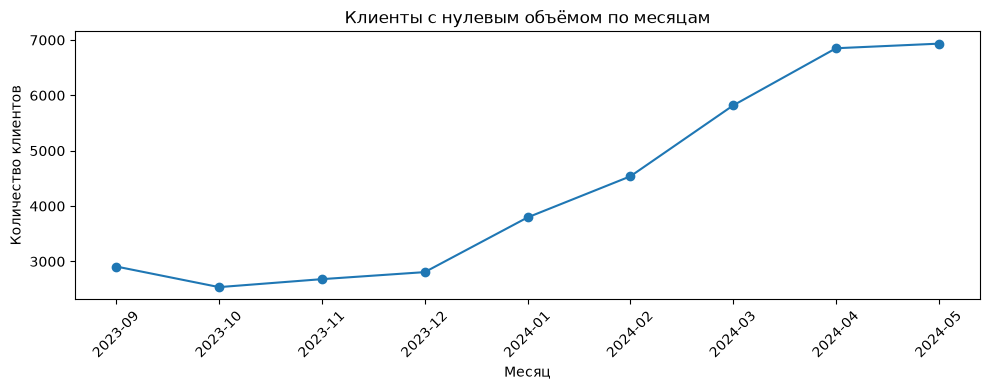

In [651]:
import matplotlib.pyplot as plt

volume_activity['Нулевой объём'].plot(marker='o', figsize=(10, 4))
plt.title('Клиенты с нулевым объёмом по месяцам')
plt.xlabel('Месяц')
plt.ylabel('Количество клиентов')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Прекращение и возобновление покупок

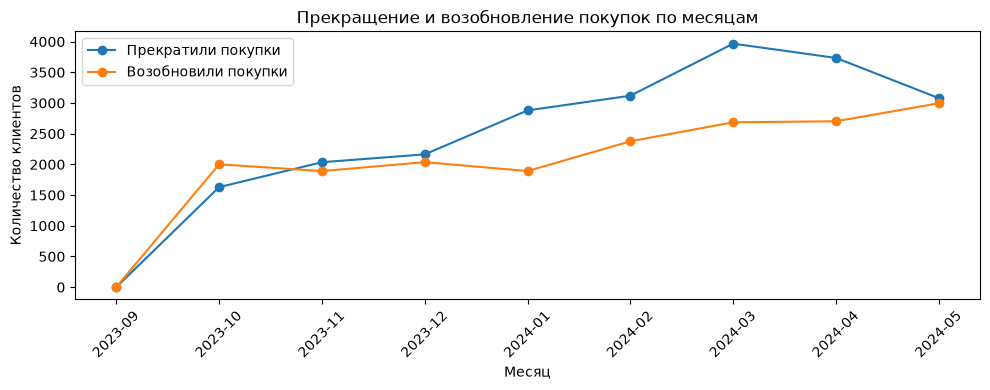

In [652]:
volume_activity[['Прекратили покупки', 'Возобновили покупки']].plot(marker='o', figsize=(10, 4))
plt.title('Прекращение и возобновление покупок по месяцам')
plt.xlabel('Месяц')
plt.ylabel('Количество клиентов')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Динамика цен и объёмов заправок

In [653]:
price_parts = []
for month, gpn_col, competitor_col in zip(volume_cols, gpn_price_cols, competitor_price_cols):
    prices = df[['Основная АЗС заправки', 'Топливо', gpn_col, competitor_col]].drop_duplicates(
        subset=['Основная АЗС заправки', 'Топливо']
    ).copy()
    prices.columns = ['АЗС', 'Топливо', 'Цена Газпромнефти', 'Цена конкурентов']
    prices['Месяц'] = month
    price_parts.append(prices)

station_prices = pd.concat(price_parts, ignore_index=True)

In [654]:
station_prices['Цена Газпромнефти'] = station_prices['Цена Газпромнефти'].mask(
    station_prices['Цена Газпромнефти'] == 0
)
station_prices['Цена конкурентов'] = station_prices['Цена конкурентов'].mask(
    station_prices['Цена конкурентов'] == 0
)
station_prices['Разница цен'] = station_prices['Цена Газпромнефти'] - station_prices['Цена конкурентов']

### Показатели по месяцам

In [655]:
monthly_metrics = station_prices.groupby('Месяц', sort=False)[
    ['Цена Газпромнефти', 'Цена конкурентов', 'Разница цен']
].mean().rename(columns={
    'Цена Газпромнефти': 'Средняя цена Газпромнефти',
    'Цена конкурентов': 'Средняя цена конкурентов',
    'Разница цен': 'Средняя разница цен'
})
monthly_metrics['Суммарный объём'] = df[volume_cols].sum()
monthly_metrics['Клиентов с положительным объёмом'] = (df[volume_cols] > 0).sum()
monthly_metrics

,Средняя цена Газпромнефти,Средняя цена конкурентов,Средняя разница цен,Суммарный объём,Клиентов с положительным объёмом
Месяц,,,,,
2023-09,58.322667,58.284243,0.038425,3998952.997,30238
2023-10,58.686395,58.431233,0.255162,4008533.170,30610
2023-11,59.237106,59.039316,0.197790,3754849.219,30466
2023-12,60.195866,59.736040,0.459826,3752009.195,30339
2024-01,60.803566,60.078291,0.725275,3175109.942,29351
2024-02,61.038938,60.265531,0.773408,2977918.134,28608
2024-03,61.641673,60.417929,1.223744,2855245.533,27327
2024-04,62.079711,60.629738,1.449973,2638482.349,26295
2024-05,62.351709,60.864345,1.487364,2730002.009,26212


### Динамика средних цен

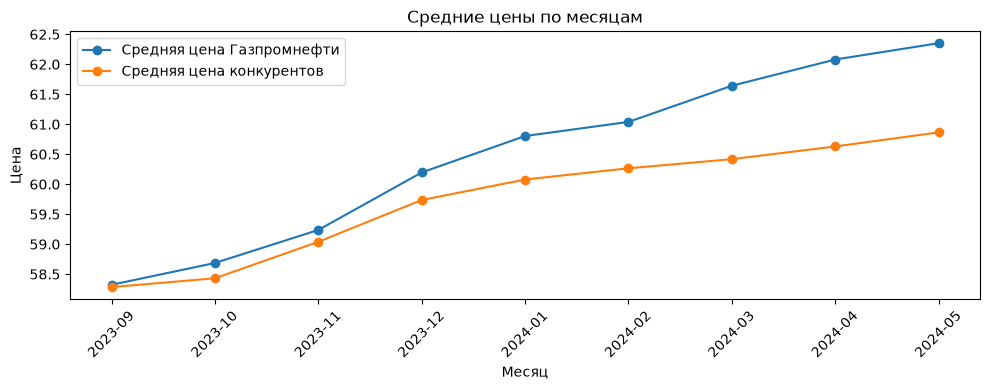

In [656]:
monthly_metrics[['Средняя цена Газпромнефти', 'Средняя цена конкурентов']].plot(
    marker='o', figsize=(10, 4)
)
plt.title('Средние цены по месяцам')
plt.xlabel('Месяц')
plt.ylabel('Цена')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Динамика средней разницы цен

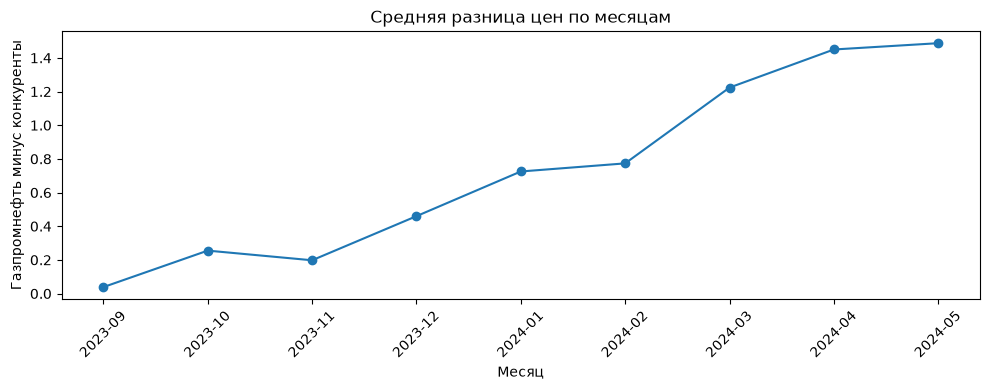

In [657]:
monthly_metrics['Средняя разница цен'].plot(marker='o', figsize=(10, 4))
plt.title('Средняя разница цен по месяцам')
plt.xlabel('Месяц')
plt.ylabel('Газпромнефть минус конкуренты')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Динамика суммарного объёма

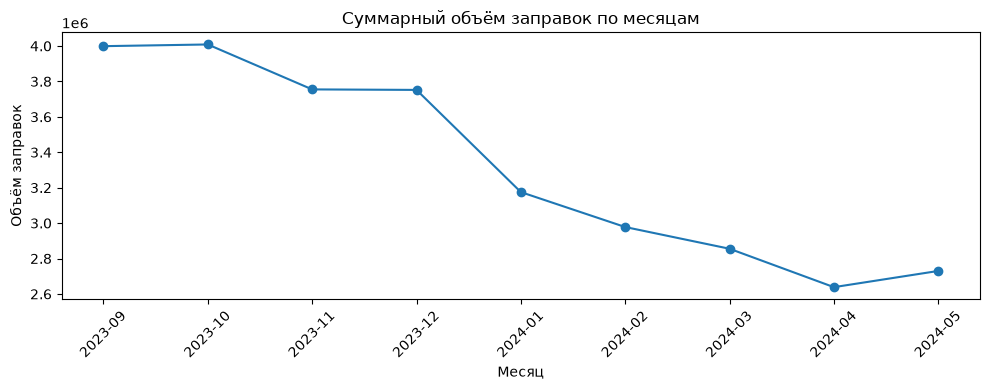

In [658]:
monthly_metrics['Суммарный объём'].plot(marker='o', figsize=(10, 4))
plt.title('Суммарный объём заправок по месяцам')
plt.xlabel('Месяц')
plt.ylabel('Объём заправок')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Разница цен и объёмы по видам топлива

In [659]:
fuel_price_diff = station_prices.groupby(['Топливо', 'Месяц'])['Разница цен'].mean()
fuel_volume = df.groupby('Топливо')[volume_cols].sum().stack()
fuel_metrics = pd.concat([
    fuel_price_diff.rename('Средняя разница цен'),
    fuel_volume.rename('Суммарный объём')
], axis=1)
fuel_metrics.index.names = ['Топливо', 'Месяц']
fuel_metrics

Средняя разница цен  Суммарный объём
Топливо Месяц                                        
АИ-92   2023-09             0.008294      1115045.089
        2023-10             0.184164      1129033.356
        2023-11             0.473622      1041721.295
        2023-12             0.761099      1033132.875
        2024-01             0.861050       880478.855
        2024-02             0.762743       823450.428
        2024-03             1.150534       785248.927
        2024-04             1.296923       732329.813
        2024-05             1.213129       749162.095
АИ-95   2023-09            -0.401248      2325769.563
        2023-10            -0.067587      2295566.579
        2023-11             0.481354      2067101.286
        2023-12             1.028762      2027223.808
        2024-01             1.285533      1762401.094
        2024-02             1.184702      1637524.163
        2024-03             1.624662      1608873.582
        2024-04             1.904349      1511279.511
        2024-05             1.838601      1598613.219
ДТ      2023-09             0.573291       558138.345
        2023-10             0.703339       583933.235
        2023-11            -0.438799       646026.638
        2023-12            -0.529287       691652.512
        2024-01            -0.066292       532229.993
        2024-02             0.317790       516943.543
        2024-03             0.851640       461123.024
        2024-04             1.107214       394873.025
        2024-05             1.399911       382226.695

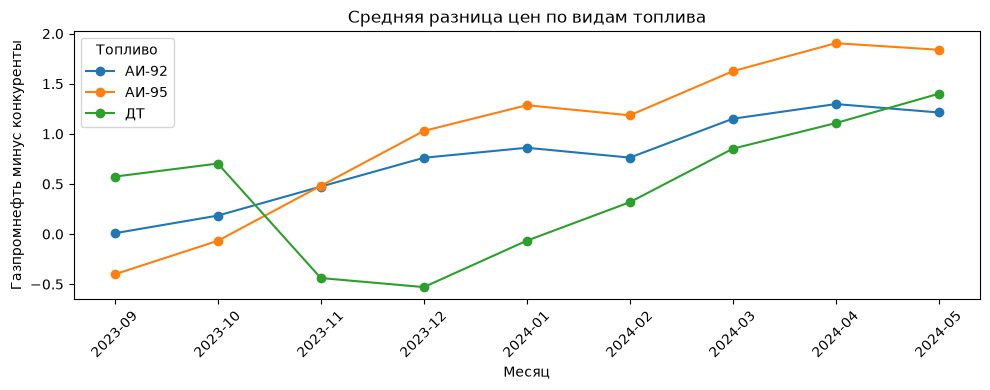

In [660]:
fuel_metrics['Средняя разница цен'].unstack('Топливо').plot(marker='o', figsize=(10, 4))
plt.title('Средняя разница цен по видам топлива')
plt.xlabel('Месяц')
plt.ylabel('Газпромнефть минус конкуренты')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Изменение разницы цен между соседними месяцами

In [661]:
price_change = monthly_metrics['Средняя разница цен'].diff().dropna()
pd.Series({
    'Увеличивалась': (price_change > 0).sum(),
    'Уменьшалась': (price_change < 0).sum(),
    'Не менялась': (price_change == 0).sum()
})

Увеличивалась    7
Уменьшалась      1
Не менялась      0
dtype: int64

In [662]:
fuel_price_change = fuel_metrics['Средняя разница цен'].unstack('Топливо').diff().iloc[1:]
pd.DataFrame({
    'Увеличивалась': (fuel_price_change > 0).sum(),
    'Уменьшалась': (fuel_price_change < 0).sum(),
    'Не менялась': (fuel_price_change == 0).sum()
})

,Увеличивалась,Уменьшалась,Не менялась
Топливо,,,
АИ-92,6,2,0
АИ-95,6,2,0
ДТ,6,2,0


## Проверка возможности восстановления нулевых цен

Нулевые цены рассматриваем как потенциальные пропуски. `df` не изменяем.

### Группы по АЗС, топливу и месяцу

In [663]:
price_group_parts = []
for month, gpn_col, competitor_col in zip(volume_cols, gpn_price_cols, competitor_price_cols):
    for price_type, price_col in [('Газпромнефть', gpn_col), ('Конкуренты', competitor_col)]:
        checks = df[['Основная АЗС заправки', 'Топливо', price_col]].copy()
        checks['Нулевая цена'] = checks[price_col] == 0
        checks['Положительная цена'] = checks[price_col].where(checks[price_col] > 0)
        groups = checks.groupby(['Основная АЗС заправки', 'Топливо']).agg({
            price_col: 'size',
            'Нулевая цена': 'sum',
            'Положительная цена': 'nunique'
        }).reset_index()
        groups.columns = ['Основная АЗС заправки', 'Топливо', 'Всего значений',
                          'Нулевых значений', 'Разных положительных цен']
        groups['Месяц'] = month
        groups['Тип цены'] = price_type
        price_group_parts.append(groups)

price_group_stats = pd.concat(price_group_parts, ignore_index=True)
price_group_stats

,Основная АЗС заправки,Топливо,Всего значений,Нулевых значений,Разных положительных цен,Месяц,Тип цены
0,АЗС_1001493,АИ-92,7,0,1,2023-09,Газпромнефть
1,АЗС_1001493,АИ-95,21,0,1,2023-09,Газпромнефть
2,АЗС_1001493,ДТ,2,0,1,2023-09,Газпромнефть
3,АЗС_10043,АИ-92,15,0,1,2023-09,Газпромнефть
4,АЗС_10043,АИ-95,33,0,1,2023-09,Газпромнефть
...,...,...,...,...,...,...,...
33061,АЗС_998492,АИ-92,16,0,1,2024-05,Конкуренты
33062,АЗС_998492,АИ-95,38,0,1,2024-05,Конкуренты
33063,АЗС_998492,ДТ,5,0,1,2024-05,Конкуренты
33064,АЗС_999492,АИ-92,26,0,1,2024-05,Конкуренты


In [664]:
price_group_stats['Групп с нулевой ценой'] = price_group_stats['Нулевых значений'] > 0
price_group_stats['С нулём и положительной ценой'] = (
    (price_group_stats['Нулевых значений'] > 0) &
    (price_group_stats['Разных положительных цен'] > 0)
)
price_group_stats['Групп только с нулями'] = (
    (price_group_stats['Нулевых значений'] > 0) &
    (price_group_stats['Нулевых значений'] == price_group_stats['Всего значений'])
)
price_group_stats['Групп с разными положительными ценами'] = (
    price_group_stats['Разных положительных цен'] > 1
)
price_group_stats['Однозначно восстановимых нулей'] = price_group_stats['Нулевых значений'].where(
    price_group_stats['Разных положительных цен'] == 1, 0
)

### Сводка по месяцам и типам цен

In [665]:
price_recovery_summary = price_group_stats.groupby(['Месяц', 'Тип цены'], sort=False)[[
    'Групп с нулевой ценой',
    'С нулём и положительной ценой',
    'Групп только с нулями',
    'Групп с разными положительными ценами',
    'Нулевых значений',
    'Однозначно восстановимых нулей'
]].sum()
price_recovery_summary

Групп с нулевой ценой  С нулём и положительной ценой  \
Месяц   Тип цены                                                             
2023-09 Газпромнефть                     15                              0   
        Конкуренты                       15                              0   
2023-10 Газпромнефть                     12                              0   
        Конкуренты                       12                              0   
2023-11 Газпромнефть                      9                              0   
        Конкуренты                        9                              0   
2023-12 Газпромнефть                      1                              0   
        Конкуренты                        1                              0   
2024-01 Газпромнефть                      0                              0   
        Конкуренты                        0                              0   
2024-02 Газпромнефть                      0                              0   
        Конкуренты                        0                              0   
2024-03 Газпромнефть                      2                              0   
        Конкуренты                        2                              0   
2024-04 Газпромнефть                      3                              0   
        Конкуренты                        3                              0   
2024-05 Газпромнефть                      5                              0   
        Конкуренты                        5                              0   

                      Групп только с нулями  \
Месяц   Тип цены                              
2023-09 Газпромнефть                     15   
        Конкуренты                       15   
2023-10 Газпромнефть                     12   
        Конкуренты                       12   
2023-11 Газпромнефть                      9   
        Конкуренты                        9   
2023-12 Газпромнефть                      1   
        Конкуренты                        1   
2024-01 Газпромнефть                      0   
        Конкуренты                        0   
2024-02 Газпромнефть                      0   
        Конкуренты                        0   
2024-03 Газпромнефть                      2   
        Конкуренты                        2   
2024-04 Газпромнефть                      3   
        Конкуренты                        3   
2024-05 Газпромнефть                      5   
        Конкуренты                        5   

                      Групп с разными положительными ценами  Нулевых значений  \
Месяц   Тип цены                                                                
2023-09 Газпромнефть                                      0               155   
        Конкуренты                                        0               155   
2023-10 Газпромнефть                                      0                99   
        Конкуренты                                        0                99   
2023-11 Газпромнефть                                      0                80   
        Конкуренты                                        0                80   
2023-12 Газпромнефть                                      0                 8   
        Конкуренты                                        0                 8   
2024-01 Газпромнефть                                      0                 0   
        Конкуренты                                        0                 0   
2024-02 Газпромнефть                                      0                 0   
        Конкуренты                                        0                 0   
2024-03 Газпромнефть                                      0                23   
        Конкуренты                                        0                23   
2024-04 Газпромнефть                                      0                43   
        Конкуренты                                        0                43   
2024-05 Газпромнефть                                      0   

In [666]:
print('Всего нулевых цен:', price_group_stats['Нулевых значений'].sum())
print('Однозначно восстановимых нулей:', price_group_stats['Однозначно восстановимых нулей'].sum())

Всего нулевых цен: 946
Однозначно восстановимых нулей: 0


`нет возмоможности восстановить нули`

## Проверка пропущенных цен по соседним месяцам

 Цены проверяем отдельно для Газпромнефти и конкурентов, без изменения `df`.

### История цен по АЗС и виду топлива

In [667]:
station_keys = ['Основная АЗС заправки', 'Топливо']
station_history = df[
    station_keys + list(gpn_price_cols) + list(competitor_price_cols)
].drop_duplicates(subset=station_keys).copy()

In [668]:
gap_parts = []
for price_type, price_cols in [('Газпромнефть', gpn_price_cols), ('Конкуренты', competitor_price_cols)]:
    prices = station_history[price_cols]
    positive = prices > 0
    has_before = positive.cummax(axis=1).shift(1, axis=1, fill_value=False)
    has_after = positive.iloc[:, ::-1].cummax(axis=1).iloc[:, ::-1].shift(-1, axis=1, fill_value=False)

    for month, price_col in zip(volume_cols, price_cols):
        missing = prices[price_col] == 0
        category = pd.Series('Нет положительных цен', index=station_history.index)
        category.loc[missing & has_before[price_col] & has_after[price_col]] = 'До и после'
        category.loc[missing & has_before[price_col] & ~has_after[price_col]] = 'Только до'
        category.loc[missing & ~has_before[price_col] & has_after[price_col]] = 'Только после'

        gaps = station_history.loc[missing, station_keys].copy()
        gaps['Месяц'] = month
        gaps['Тип цены'] = price_type
        gaps['Категория'] = category.loc[missing]
        gap_parts.append(gaps)

station_gaps = pd.concat(gap_parts, ignore_index=True)
station_gaps

,Основная АЗС заправки,Топливо,Месяц,Тип цены,Категория
0,АЗС_679332,АИ-95,2023-09,Газпромнефть,Только после
1,АЗС_798392,АИ-95,2023-09,Газпромнефть,Только после
2,АЗС_865425,АИ-95,2023-09,Газпромнефть,Только после
3,АЗС_432209,АИ-92,2023-09,Газпромнефть,Только после
4,АЗС_798392,АИ-92,2023-09,Газпромнефть,Только после
...,...,...,...,...,...
89,АЗС_345165,АИ-95,2024-05,Конкуренты,Только до
90,АЗС_586286,АИ-95,2024-05,Конкуренты,Только до
91,АЗС_345165,АИ-92,2024-05,Конкуренты,Только до
92,АЗС_586286,АИ-92,2024-05,Конкуренты,Только до


### Количество пропусков по категориям

Уникальный пропуск — одна нулевая цена для сочетания АЗС, топлива и месяца. Клиентские значения считаются отдельно, так как одну цену могут иметь несколько клиентов.

In [669]:
client_gaps = station_gaps.merge(
    df[station_keys + ['Клиент']], on=station_keys, how='left', validate='many_to_many'
)
gap_summary = pd.DataFrame({
    'Уникальных пропусков': station_gaps.groupby(['Тип цены', 'Категория']).size(),
    'Нулевых цен у клиентов': client_gaps.groupby(['Тип цены', 'Категория']).size(),
    'Затронутых клиентов': client_gaps.groupby(['Тип цены', 'Категория'])['Клиент'].nunique(),
    'Затронутых АЗС': client_gaps.groupby(['Тип цены', 'Категория'])['Основная АЗС заправки'].nunique()
})
category_order = ['До и после', 'Только до', 'Только после', 'Нет положительных цен']
summary_index = pd.MultiIndex.from_product(
    [['Газпромнефть', 'Конкуренты'], category_order], names=['Тип цены', 'Категория']
)
gap_summary = gap_summary.reindex(summary_index, fill_value=0)
gap_summary

Уникальных пропусков  \
Тип цены     Категория                                     
Газпромнефть До и после                                5   
             Только до                                 5   
             Только после                             37   
             Нет положительных цен                     0   
Конкуренты   До и после                                5   
             Только до                                 5   
             Только после                             37   
             Нет положительных цен                     0   

                                    Нулевых цен у клиентов  \
Тип цены     Категория                                       
Газпромнефть До и после                                 66   
             Только до                                  65   
             Только после                              342   
             Нет положительных цен                       0   
Конкуренты   До и после                                 66   
             Только до                                  65   
             Только после                              342   
             Нет положительных цен                       0   

                                    Затронутых клиентов  Затронутых АЗС  
Тип цены     Категория                                                   
Газпромнефть До и после                              66               2  
             Только до                               65               2  
             Только после                           155               6  
             Нет положительных цен                    0               0  
Конкуренты   До и после                              66               2  
             Только до                               65               2  
             Только после                           155               6  
             Нет положительных цен                    0               0

### Возможность линейной интерполяции

Линейная интерполяция возможна при положительных ценах с обеих сторон пропуска. Здесь считаем такие случаи, но цены не заполняем.

In [670]:
gap_summary.xs('До и после', level='Категория')[[
    'Уникальных пропусков', 'Нулевых цен у клиентов',
    'Затронутых клиентов', 'Затронутых АЗС'
]]

,Уникальных пропусков,Нулевых цен у клиентов,Затронутых клиентов,Затронутых АЗС
Тип цены,,,,
Газпромнефть,5,66,66,2
Конкуренты,5,66,66,2


## Обработка нулевых цен

In [671]:
df_before = df.copy(deep=True)
df_clean = df.copy(deep=True)

In [672]:
price_cols = list(gpn_price_cols) + list(competitor_price_cols)
df_clean[price_cols] = df_clean[price_cols].mask(df_clean[price_cols] == 0)

просто заменяем нули на Nan

## Географический анализ

### Подразделения, АЗС и клиенты

In [673]:
geo_counts = df_clean.groupby('Подразделение').agg(
    АЗС=('Основная АЗС заправки', 'nunique'),
    Клиентов=('Клиент', 'nunique')
).sort_values('Клиентов', ascending=False)
geo_counts

,АЗС,Клиентов
Подразделение,,
Бишкек,136,8169
Астана,92,5104
Пекин,74,4075
Ереван,82,3755
Ташкент,58,2574
Москва,44,2287
Ашхабад,59,2281
Душанбе,41,1806
Минск,36,1551


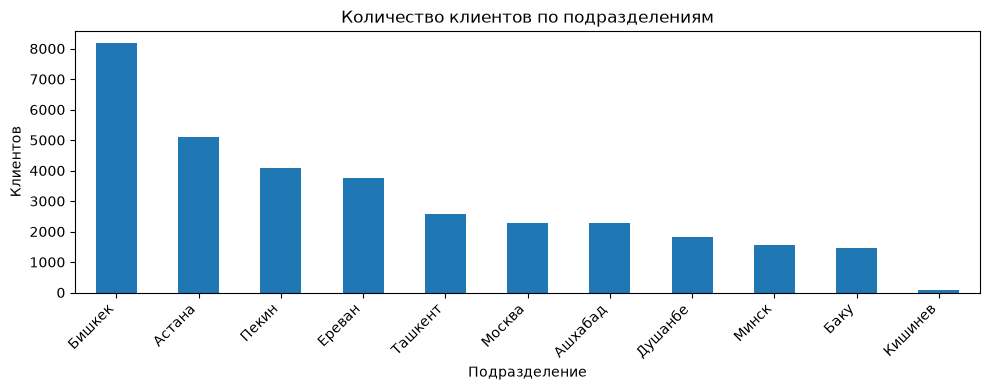

In [674]:
import matplotlib.pyplot as plt

geo_counts['Клиентов'].plot.bar(figsize=(10, 4))
plt.title('Количество клиентов по подразделениям')
plt.xlabel('Подразделение')
plt.ylabel('Клиентов')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### Объём заправок по подразделениям и месяцам

In [675]:
geo_volume = df_clean.groupby('Подразделение')[volume_cols].sum()
geo_volume

,2023-09,2023-10,2023-11,2023-12,2024-01,2024-02,2024-03,2024-04,2024-05
Подразделение,,,,,,,,,
Астана,655016.564,658452.431,618193.063,606881.708,503077.598,443597.601,421594.326,359517.728,367563.235
Ашхабад,242426.210,253525.120,248550.760,239055.490,197678.830,177792.080,167206.130,155776.970,152676.100
Баку,182735.960,175265.670,171253.090,187345.790,165433.630,162492.970,156407.630,135836.840,128304.730
Бишкек,1081191.510,1060525.320,926700.430,913792.260,751489.450,749822.280,742092.050,717725.260,736581.250
Душанбе,163659.810,174133.970,210524.530,233673.750,207474.120,176000.820,161072.400,163739.030,174192.130
Ереван,390686.320,407704.670,400896.660,410182.880,347703.540,324157.350,312605.380,281747.280,287347.610
Кишинев,5269.250,6143.060,7136.740,8930.750,7695.180,8718.040,7827.050,7660.430,6701.930
Минск,197278.670,195479.070,166990.130,164256.060,138572.410,131665.220,131848.740,126547.560,134487.710
Москва,283057.843,292031.779,265734.136,258650.687,220670.164,208157.193,190721.547,174730.591,195552.524


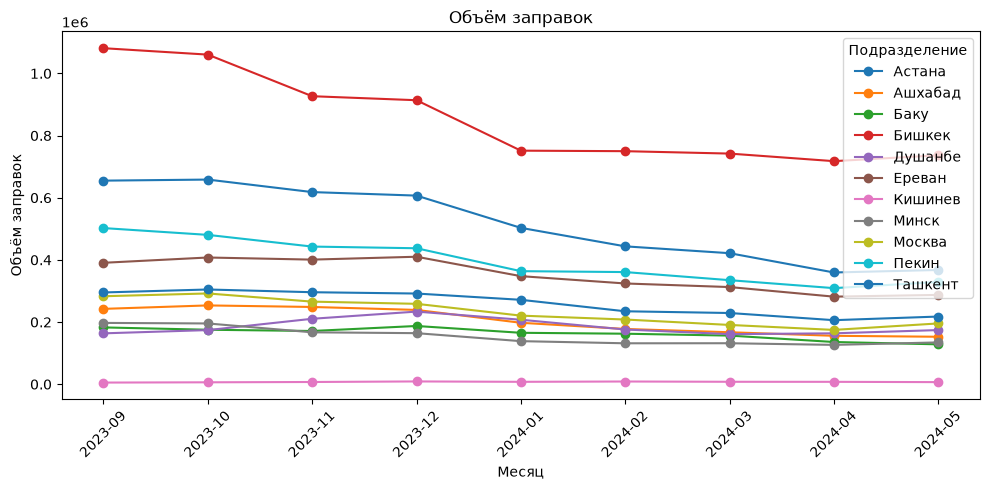

In [676]:
top_divisions = geo_volume.sum(axis=1).index
geo_volume.loc[top_divisions].T.plot(marker='o', figsize=(10, 5))
plt.title('Объём заправок')
plt.xlabel('Месяц')
plt.ylabel('Объём заправок')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Диапазоны цен по подразделениям и видам топлива

Для цен берём одну запись на АЗС, топливо и месяц. `NaN` не участвуют в поиске минимума и максимума. В заголовках исходного XLSB обе цены указаны в рублях за литр.

In [677]:
geo_price_parts = []
for month, gpn_col, competitor_col in zip(volume_cols, gpn_price_cols, competitor_price_cols):
    prices = df_clean[[
        'Подразделение', 'Основная АЗС заправки', 'Топливо', gpn_col, competitor_col
    ]].drop_duplicates(subset=['Основная АЗС заправки', 'Топливо']).copy()
    prices.columns = ['Подразделение', 'АЗС', 'Топливо', 'Цена Газпромнефти', 'Цена конкурентов']
    prices['Месяц'] = month
    geo_price_parts.append(prices)

geo_prices = pd.concat(geo_price_parts, ignore_index=True)

In [678]:
geo_price_ranges = geo_prices.groupby(['Подразделение', 'Топливо'])[[
    'Цена Газпромнефти', 'Цена конкурентов'
]].agg(['min', 'max', 'mean']).round(2)
geo_price_ranges

Цена Газпромнефти               Цена конкурентов         \
                                    min    max   mean              min    max   
Подразделение Топливо                                                           
Астана        АИ-92               50.21  55.83  53.23            49.50  55.67   
              АИ-95               54.02  60.71  57.98            53.40  63.78   
              ДТ                  65.80  75.68  70.74            60.73  84.88   
Ашхабад       АИ-92               48.51  56.27  51.94            46.86  55.39   
              АИ-95               53.79  60.67  57.44            50.80  60.05   
              ДТ                  64.55  71.36  68.32            57.00  71.05   
Баку          АИ-92               53.79  58.06  56.30            48.60  58.67   
              АИ-95               59.17  64.12  61.89            55.60  64.98   
              ДТ                  61.02  66.76  64.29            55.94  68.12   
Бишкек        АИ-92               51.21  59.74  55.04            49.30  59.96   
              АИ-95               54.77  71.33  61.18            52.74  74.20   
              ДТ                  63.37  75.79  67.93            60.20  75.85   
Душанбе       АИ-92               49.99  54.61  52.51            50.48  56.15   
              АИ-95               54.67  59.54  57.34            54.64  61.37   
              ДТ                  65.65  71.33  68.72            65.60  73.64   
Ереван        АИ-92               51.47  57.61  54.69            49.50  69.01   
              АИ-95               56.02  62.52  59.33            53.50  64.02   
              ДТ                  62.79  74.09  69.21            59.42  77.67   
Кишинев       АИ-92               52.75  56.85  54.39            51.19  56.10   
              АИ-95               56.66  63.35  59.13            57.83  61.30   
              ДТ                  63.34  67.73  65.25            62.97  67.13   
Минск         АИ-92               52.69  58.12  55.93            49.80  57.95   
              АИ-95               56.59  63.80  60.92            52.80  62.18   
              ДТ                  65.65  73.11  69.32            56.80  71.28   
Москва        АИ-92               49.74  56.00  53.61            49.00  55.85   
              АИ-95               53.12  60.59  57.94            53.50  60.48   
              ДТ                  66.80  76.59  72.33            64.00  76.49   
Пекин         АИ-92               51.36  58.25  54.91            48.83  58.55   
              АИ-95               54.37  62.81  59.06            53.29  63.11   
              ДТ                  63.27  73.22  66.66            54.50  72.89   
Ташкент       АИ-92               45.65  62.60  54.89            42.37  60.25   
              АИ-95               49.16  65.90  60.03            48.75  68.50   
              ДТ                  66.38  87.84  71.14            63.29  90.00   

                              
                        mean  
Подразделение Топливо         
Астана        АИ-92    52.97  
              АИ-95    57.48  
              ДТ       72.21  
Ашхабад       АИ-92    50.39  
              АИ-95    55.27  
              ДТ       65.68  
Баку          АИ-92    53.35  
              АИ-95    59.77  
              ДТ       62.34  
Бишкек        АИ-92    54.59  
              АИ-95    60.88  
              ДТ       67.39  
Душанбе       АИ-92    52.96  
              АИ-95    57.33  
              ДТ       69.55  
Ереван        АИ-92    53.47  
              АИ-95    57.47  
              ДТ       68.83  
Кишинев       АИ-92    53.42  
              АИ-95    58.90  
              ДТ       64.92  
Минск         АИ-92    55.20  
              АИ-95    59.66  
              ДТ       68.31  
Москва        АИ-92    53.23  
              АИ-95    57.26  
              ДТ       71.60  
Пекин         АИ-92    53.92  
              АИ-95    58.02  
              ДТ       65.58  
Ташкент       АИ-92    53.96  
              АИ-95    58.72  
              ДТ    

### Пропущенные цены по подразделениям

In [679]:
missing_client_prices = pd.DataFrame({
    'Газпромнефть, записи клиентов': df_clean[gpn_price_cols].isna().groupby(
        df_clean['Подразделение']
    ).sum().sum(axis=1),
    'Конкуренты, записи клиентов': df_clean[competitor_price_cols].isna().groupby(
        df_clean['Подразделение']
    ).sum().sum(axis=1)
})
missing_client_prices

,"Газпромнефть, записи клиентов","Конкуренты, записи клиентов"
Подразделение,,
Астана,10,10
Ашхабад,0,0
Баку,0,0
Бишкек,56,56
Душанбе,33,33
Ереван,153,153
Кишинев,0,0
Минск,0,0
Москва,0,0


In [680]:
missing_station_prices = geo_prices[[
    'Цена Газпромнефти', 'Цена конкурентов'
]].isna().groupby(geo_prices['Подразделение']).sum()
missing_station_prices.columns = [
    'Газпромнефть, уникальные АЗС/топливо/месяц',
    'Конкуренты, уникальные АЗС/топливо/месяц'
]
missing_station_prices

,"Газпромнефть, уникальные АЗС/топливо/месяц","Конкуренты, уникальные АЗС/топливо/месяц"
Подразделение,,
Астана,2,2
Ашхабад,0,0
Баку,0,0
Бишкек,3,3
Душанбе,9,9
Ереван,12,12
Кишинев,0,0
Минск,0,0
Москва,0,0


мы по итогу в этих случаях используем линейную инерполяцию?!?!

### Подразделения для географической проверки

Это предварительный список по названиям городов. Принадлежность к СНГ и расположение АЗС нужно проверить отдельно. Единица цен в исходном XLSB — руб/литр.

In [681]:
cis_candidates = [
    'Астана', 'Ашхабад', 'Баку', 'Бишкек', 'Душанбе',
    'Ереван', 'Кишинев', 'Минск', 'Москва', 'Ташкент'
]
china_candidates = ['Пекин']
print('Возможная связь со странами СНГ:', sorted(
    df_clean.loc[df_clean['Подразделение'].isin(cis_candidates), 'Подразделение'].unique()
))
print('Возможная связь с Китаем:', sorted(
    df_clean.loc[df_clean['Подразделение'].isin(china_candidates), 'Подразделение'].unique()
))

Возможная связь со странами СНГ: ['Астана', 'Ашхабад', 'Баку', 'Бишкек', 'Душанбе', 'Ереван', 'Кишинев', 'Минск', 'Москва', 'Ташкент']
Возможная связь с Китаем: ['Пекин']


сомнительное деление, могли рассмотреть отдельно евразийский союз, но тут явно видно, что содержательно никаких отличий нет 

## Проверка сопоставимости цен между подразделениями

Используем `geo_prices`, полученную из `df_clean`: одна запись на АЗС, вид топлива и месяц. По заголовкам исходного XLSB цены указаны в рублях за литр.

### Средняя цена Газпромнефти по месяцам

In [682]:
division_prices = geo_prices.groupby(['Подразделение', 'Топливо', 'Месяц'])[
    'Цена Газпромнефти'
].mean().rename('Средняя цена Газпромнефти').reset_index()
division_prices

,Подразделение,Топливо,Месяц,Средняя цена Газпромнефти
0,Астана,АИ-92,2023-09,51.289674
1,Астана,АИ-92,2023-10,51.603804
2,Астана,АИ-92,2023-11,52.112065
3,Астана,АИ-92,2023-12,52.956413
4,Астана,АИ-92,2024-01,53.515217
...,...,...,...,...
292,Ташкент,ДТ,2024-01,71.867500
293,Ташкент,ДТ,2024-02,72.126136
294,Ташкент,ДТ,2024-03,72.199318
295,Ташкент,ДТ,2024-04,72.529545


### Средняя цена  по подразделениям в разрезе типа топлива 

In [683]:
division_prices['Топливо'].unique()

<StringArray>
['АИ-92', 'АИ-95', 'ДТ']
Length: 3, dtype: str

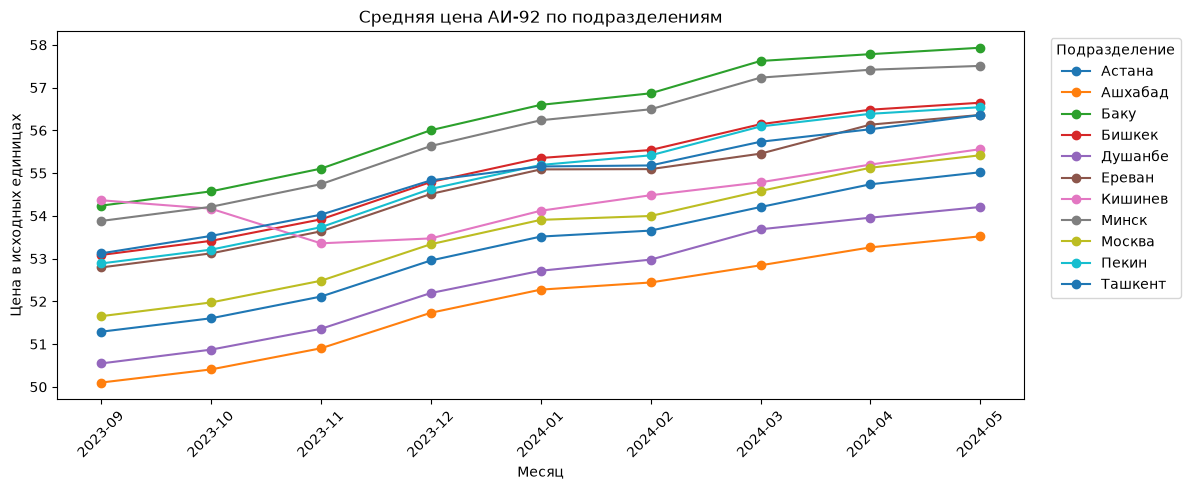

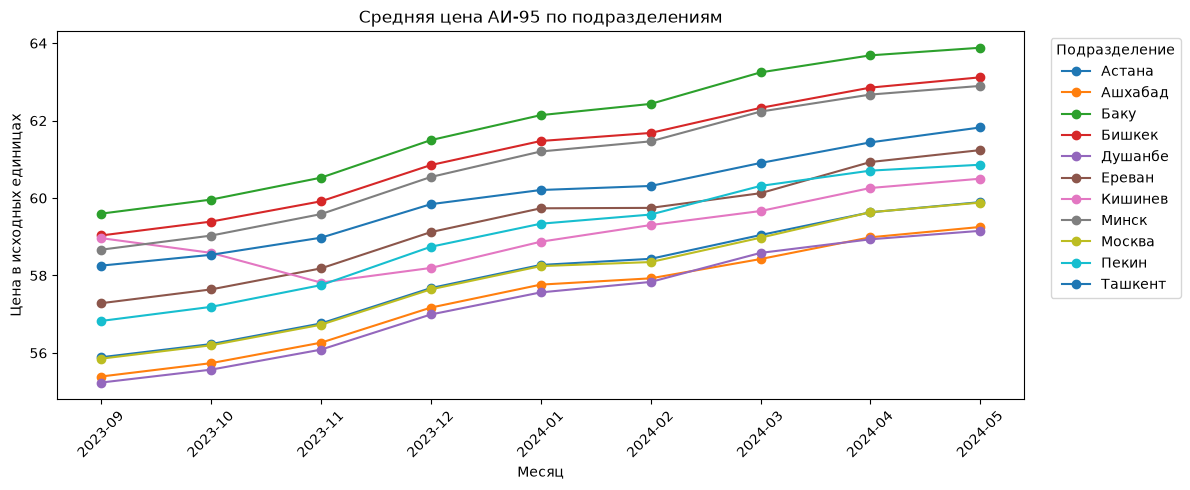

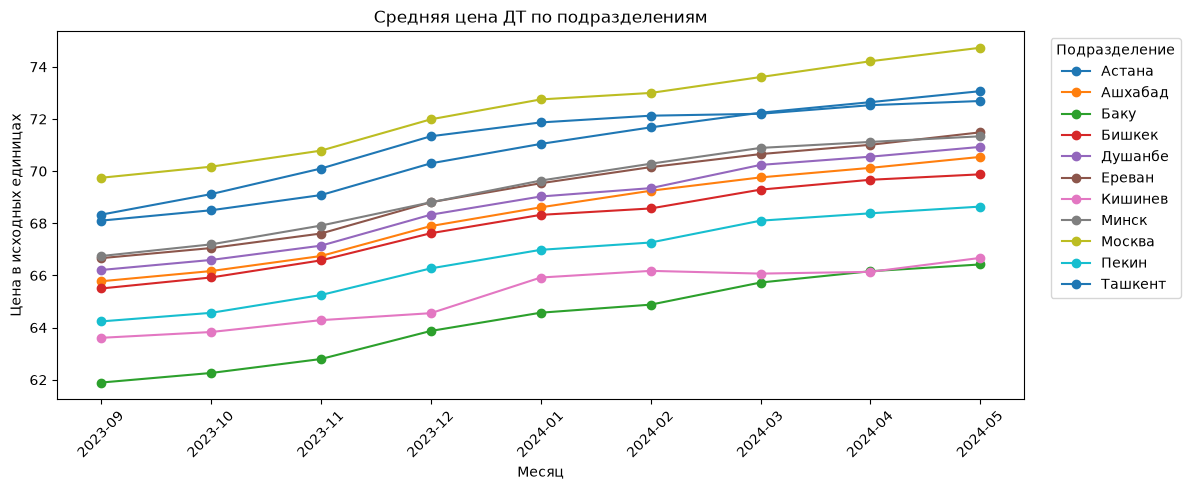

In [684]:
for type in division_prices['Топливо'].unique():
    prices = division_prices[division_prices['Топливо'] == type].pivot(
    index='Месяц', columns='Подразделение', values='Средняя цена Газпромнефти')
    prices.plot(marker='o', figsize=(12, 5))
    plt.title(f'Средняя цена {type} по подразделениям')
    plt.xlabel('Месяц')
    plt.ylabel('Цена в исходных единицах')
    plt.xticks(rotation=45)
    plt.legend(title='Подразделение', bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

здесь только кишенёв выбивается из общей тенденции 

### Средние цены и их месячные изменения

In [685]:
division_prices['Изменение к предыдущему месяцу'] = division_prices.groupby(
    ['Подразделение', 'Топливо']
)['Средняя цена Газпромнефти'].diff()
division_prices

,Подразделение,Топливо,Месяц,Средняя цена Газпромнефти,Изменение к предыдущему месяцу
0,Астана,АИ-92,2023-09,51.289674,NaN
1,Астана,АИ-92,2023-10,51.603804,0.314130
2,Астана,АИ-92,2023-11,52.112065,0.508261
3,Астана,АИ-92,2023-12,52.956413,0.844348
4,Астана,АИ-92,2024-01,53.515217,0.558804
...,...,...,...,...,...
292,Ташкент,ДТ,2024-01,71.867500,0.530000
293,Ташкент,ДТ,2024-02,72.126136,0.258636
294,Ташкент,ДТ,2024-03,72.199318,0.073182
295,Ташкент,ДТ,2024-04,72.529545,0.330227


### Совпадающие истории цен на разных АЗС

Сравниваем цены внутри одного вида топлива. Полное совпадение означает одинаковые цены во всех девяти месяцах; ряды с `NaN` исключаем из этой проверки.

In [686]:
station_price_series = geo_prices.pivot(
    index=['Подразделение', 'АЗС', 'Топливо'],
    columns='Месяц',
    values='Цена Газпромнефти'
).reindex(columns=volume_cols)
complete_price_series = station_price_series.dropna().reset_index()
identical_price_series = complete_price_series[
    complete_price_series.duplicated(subset=['Топливо'] + list(volume_cols), keep=False)
].copy()
identical_price_series['Группа ряда'] = identical_price_series.groupby(
    ['Топливо'] + list(volume_cols), sort=False
).ngroup() + 1

In [687]:
identical_series_summary = identical_price_series.groupby('Группа ряда').agg(
    АЗС=('АЗС', 'nunique'),
    Подразделений=('Подразделение', 'nunique'),
    Топливо=('Топливо', 'first')
)
print('Полных историй цен:', len(complete_price_series))
print('Групп полностью одинаковых историй:', len(identical_series_summary))
print('Групп с разными АЗС:', (identical_series_summary['АЗС'] > 1).sum())
print('Групп из разных подразделений:', (identical_series_summary['Подразделений'] > 1).sum())
identical_price_series[['Группа ряда', 'Подразделение', 'АЗС', 'Топливо']].head(20)

Полных историй цен: 1813
Групп полностью одинаковых историй: 219
Групп с разными АЗС: 219
Групп из разных подразделений: 11


,Группа ряда,Подразделение,АЗС,Топливо
3,1,Астана,АЗС_1082534,АИ-92
4,2,Астана,АЗС_1082534,АИ-95
6,3,Астана,АЗС_1120553,АИ-92
8,4,Астана,АЗС_1120553,ДТ
9,3,Астана,АЗС_1122554,АИ-92
11,5,Астана,АЗС_1122554,ДТ
13,6,Астана,АЗС_1129557,АИ-95
14,7,Астана,АЗС_1129557,ДТ
15,8,Астана,АЗС_1131558,АИ-92
16,2,Астана,АЗС_1131558,АИ-95


### Примеры совпадений между подразделениями

In [688]:
cross_division_groups = identical_series_summary.index[identical_series_summary['Подразделений'] > 1]
identical_price_series.loc[
    identical_price_series['Группа ряда'].isin(cross_division_groups),
    ['Группа ряда', 'Подразделение', 'АЗС', 'Топливо']
].head(20)

,Группа ряда,Подразделение,АЗС,Топливо
4,2,Астана,АЗС_1082534,АИ-95
13,6,Астана,АЗС_1129557,АИ-95
16,2,Астана,АЗС_1131558,АИ-95
42,2,Астана,АЗС_1149567,АИ-95
247,41,Астана,АЗС_650318,АИ-95
304,54,Ашхабад,АЗС_12756,АИ-92
419,64,Баку,АЗС_1110548,АИ-92
422,65,Баку,АЗС_1112549,АИ-92
425,65,Баку,АЗС_1113549,АИ-92
428,64,Баку,АЗС_1150568,АИ-92


## Анализ выбросов

Используем агрегированные объёмы по АЗС и топливу из `station_month`. Это объёмы клиентов выборки, сгруппированных по основной АЗС заправки. Процентное изменение отсутствует, если объём предыдущего месяца равен нулю; наблюдения не удаляем. Единица цен в заголовках исходного XLSB — руб/литр.

### Распределения и процентили

In [689]:
outlier_stats = pd.DataFrame({
    'Объём заправок, л': station_month['Объём'].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]),
    'Изменение объёма, %': station_month['Изменение объёма, %'].describe(
        percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]
    ),
    'Изменение разницы цен': station_month['Изменение разницы цен'].describe(
        percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]
    )
}).loc[['count', 'min', 'max', '50%', '1%', '5%', '95%', '99%']]
outlier_stats = outlier_stats.rename(index={'50%': 'Медиана'})
outlier_stats

,"Объём заправок, л","Изменение объёма, %",Изменение разницы цен
count,16533.00000,14516.000000,14644.0000
min,0.00000,-100.000000,-11.4900
max,18499.44500,106463.000000,15.4800
Медиана,1221.83000,-4.163874,0.1400
1%,0.00000,-87.857622,-2.7314
5%,94.89200,-51.742943,-0.8100
95%,5603.32200,69.806692,1.4585
99%,8791.42048,228.383423,2.7057


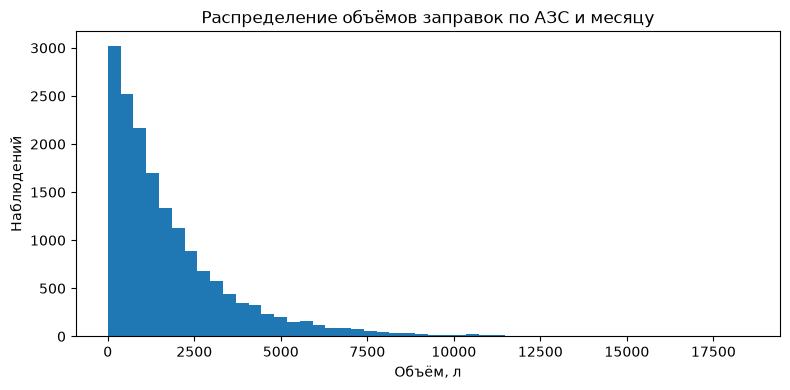

In [690]:
plt.figure(figsize=(8, 4))
plt.hist(station_month['Объём'], bins=50)
plt.title('Распределение объёмов заправок по АЗС и месяцу')
plt.xlabel('Объём, л')
plt.ylabel('Наблюдений')
plt.tight_layout()
plt.show()

### Наибольшие процентные изменения объёма

In [691]:
largest_volume_changes = station_month[
    station_month['Изменение объёма, %'].notna()
].copy()
largest_volume_changes['Модуль изменения объёма, %'] = (
    largest_volume_changes['Изменение объёма, %'].abs()
)
largest_volume_changes.nlargest(20, 'Модуль изменения объёма, %')[[
    'АЗС', 'Топливо', 'Подразделение', 'Месяц',
    'Объём предыдущего месяца', 'Объём', 'Изменение объёма, %'
]]

,АЗС,Топливо,Подразделение,Месяц,Объём предыдущего месяца,Объём,"Изменение объёма, %"
4614,АЗС_705345,ДТ,Душанбе,2023-11,2.00,2131.26,106463.000000
7368,АЗС_1137561,ДТ,Астана,2024-01,20.88,1915.72,9074.904215
10872,АЗС_1048517,ДТ,Ташкент,2024-02,28.07,994.45,3442.750267
8273,АЗС_695340,ДТ,Душанбе,2024-01,80.98,2635.05,3153.951593
9796,АЗС_1598792,АИ-92,Бишкек,2024-02,12.88,250.48,1844.720497
4672,АЗС_1171578,ДТ,Ереван,2023-11,45.01,813.99,1708.464786
10653,АЗС_10143,ДТ,Пекин,2024-02,149.83,2568.92,1614.556497
2713,АЗС_657321,ДТ,Душанбе,2023-10,30.00,505.33,1584.433333
3878,АЗС_631308,ДТ,Астана,2023-11,14.34,234.96,1538.493724
12059,АЗС_327156,ДТ,Ереван,2024-03,36.00,574.00,1494.444444


### Наибольшие скачки разницы цен

Показаны только соседние месяцы с известными ценами в обоих месяцах.

In [692]:
price_jumps = station_month.copy()
price_jumps['Предыдущий месяц'] = price_jumps.groupby(['АЗС', 'Топливо'])['Месяц'].shift(1)
price_jumps['Цена Газпромнефти ранее'] = price_jumps.groupby(
    ['АЗС', 'Топливо']
)['Цена Газпромнефти'].shift(1)
price_jumps['Цена конкурентов ранее'] = price_jumps.groupby(
    ['АЗС', 'Топливо']
)['Цена конкурентов'].shift(1)
price_jumps['Изменение цены Газпромнефти'] = (
    price_jumps['Цена Газпромнефти'] - price_jumps['Цена Газпромнефти ранее']
).round(2)
price_jumps['Изменение цены конкурентов'] = (
    price_jumps['Цена конкурентов'] - price_jumps['Цена конкурентов ранее']
).round(2)
price_jumps['Модуль изменения разницы цен'] = price_jumps['Изменение разницы цен'].abs()
price_jumps.nlargest(15, 'Модуль изменения разницы цен')[[
    'АЗС', 'Топливо', 'Подразделение', 'Предыдущий месяц', 'Месяц',
    'Цена Газпромнефти ранее', 'Цена Газпромнефти',
    'Цена конкурентов ранее', 'Цена конкурентов',
    'Изменение цены Газпромнефти', 'Изменение цены конкурентов', 'Изменение разницы цен'
]]

,АЗС,Топливо,Подразделение,Предыдущий месяц,Месяц,Цена Газпромнефти ранее,Цена Газпромнефти,Цена конкурентов ранее,Цена конкурентов,Изменение цены Газпромнефти,Изменение цены конкурентов,Изменение разницы цен
2838,АЗС_1176581,АИ-92,Ереван,2023-09,2023-10,53.42,53.76,69.01,53.87,0.34,-15.14,15.48
7465,АЗС_574280,ДТ,Астана,2023-12,2024-01,69.07,69.79,77.94,65.98,0.72,-11.96,12.68
12844,АЗС_885435,ДТ,Ташкент,2024-02,2024-03,78.63,67.79,80.75,81.40,-10.84,0.65,-11.49
3906,АЗС_643314,ДТ,Астана,2023-10,2023-11,69.42,69.96,71.90,83.92,0.54,12.02,-11.48
3791,АЗС_574280,ДТ,Астана,2023-10,2023-11,67.30,67.83,67.30,78.98,0.53,11.68,-11.15
3924,АЗС_650318,ДТ,Астана,2023-10,2023-11,69.36,69.92,72.92,83.60,0.56,10.68,-10.12
15189,АЗС_1088537,ДТ,Бишкек,2024-04,2024-05,69.96,70.11,69.96,60.65,0.15,-9.31,9.46
3524,АЗС_1048517,ДТ,Ташкент,2023-09,2023-10,66.38,76.54,68.30,69.13,10.16,0.83,9.33
14928,АЗС_643314,ДТ,Астана,2024-04,2024-05,73.60,74.05,83.45,74.68,0.45,-8.77,9.22
10872,АЗС_1048517,ДТ,Ташкент,2024-01,2024-02,82.32,72.97,74.37,74.13,-9.35,-0.24,-9.11


### Графики изменений

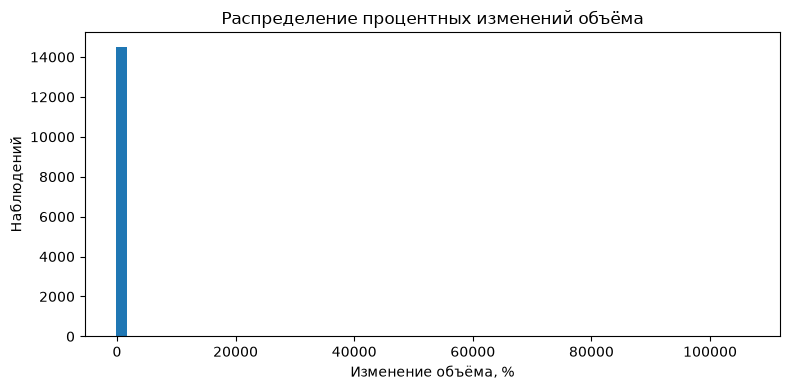

In [693]:
plt.figure(figsize=(8, 4))
plt.hist(station_month['Изменение объёма, %'].dropna(), bins=60)
plt.title('Распределение процентных изменений объёма')
plt.xlabel('Изменение объёма, %')
plt.ylabel('Наблюдений')
plt.tight_layout()
plt.show()

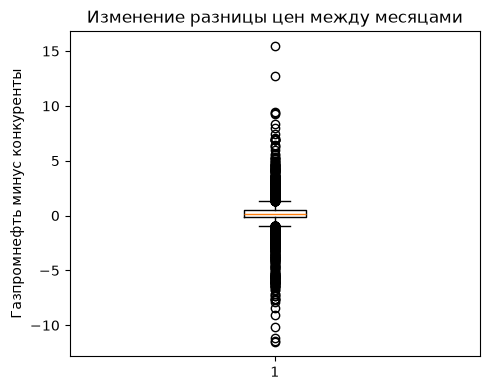

In [694]:
plt.figure(figsize=(5, 4))
plt.boxplot(station_month['Изменение разницы цен'].dropna())
plt.title('Изменение разницы цен между месяцами')
plt.ylabel('Газпромнефть минус конкуренты')
plt.tight_layout()
plt.show()

На диаграмме ниже ось Y ограничена от −100% до +100% только для отображения. В расчётах все значения сохранены.

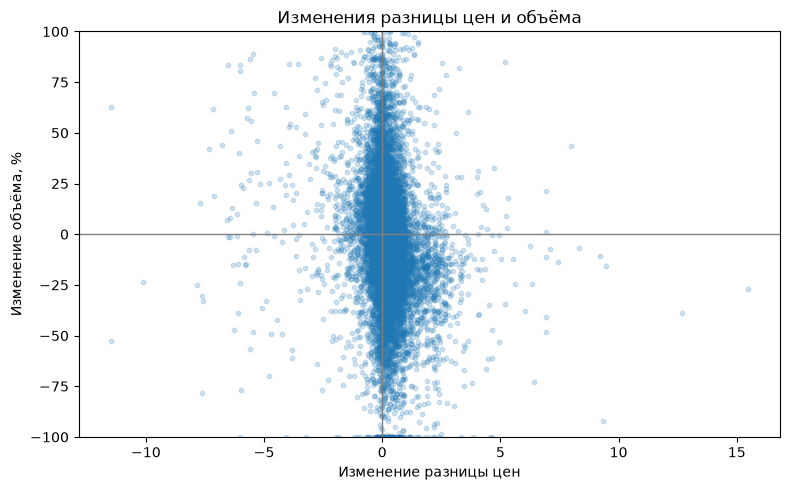

In [695]:
scatter_data = station_month[
    station_month['Изменение разницы цен'].notna() &
    station_month['Изменение объёма, %'].notna()
]
plt.figure(figsize=(8, 5))
plt.scatter(scatter_data['Изменение разницы цен'],
            scatter_data['Изменение объёма, %'], alpha=0.2, s=10)
plt.axhline(0, color='gray', linewidth=1)
plt.axvline(0, color='gray', linewidth=1)
plt.ylim(-100, 100)
plt.title('Изменения разницы цен и объёма')
plt.xlabel('Изменение разницы цен')
plt.ylabel('Изменение объёма, %')
plt.tight_layout()
plt.show()

### Диагностика минимального объёма предыдущего месяца

Пороги применяются только к временным срезам переходов с известными ценами. Строка `>0` служит базой для сравнения; это не правила очистки.

In [696]:
positive_previous_volume = comparable[comparable['Объём предыдущего месяца'] > 0]
threshold_rows = []
for minimum in [0, 20, 100, 500]:
    selected = positive_previous_volume[
        positive_previous_volume['Объём предыдущего месяца'] >= minimum
    ]
    threshold_rows.append({
        'Минимум предыдущего объёма, л': '>0' if minimum == 0 else str(minimum),
        'Наблюдений': len(selected),
        'Мин. изменения объёма, %': selected['Изменение объёма, %'].min(),
        '1% изменения объёма': selected['Изменение объёма, %'].quantile(0.01),
        'Медиана изменения объёма, %': selected['Изменение объёма, %'].median(),
        '99% изменения объёма': selected['Изменение объёма, %'].quantile(0.99),
        'Макс. изменения объёма, %': selected['Изменение объёма, %'].max(),
        'Медиана изменения разницы цен': selected['Изменение разницы цен'].median()
    })
threshold_stats = pd.DataFrame(threshold_rows).set_index('Минимум предыдущего объёма, л')
threshold_stats

,Наблюдений,"Мин. изменения объёма, %",1% изменения объёма,"Медиана изменения объёма, %",99% изменения объёма,"Макс. изменения объёма, %",Медиана изменения разницы цен
"Минимум предыдущего объёма, л",,,,,,,
>0,14464,-100.0,-87.952986,-4.185839,226.875290,106463.000000,0.14
20,14427,-100.0,-86.112573,-4.224549,208.862784,9074.904215,0.14
100,13912,-100.0,-79.589292,-4.596775,145.239267,1614.556497,0.14
500,11275,-100.0,-66.787761,-5.131212,84.024087,681.530652,0.15


### Проверка происхождения выбросов

Проверяем повторения ключей, одинаковость цен внутри АЗС и топлива и сохранение месячных сумм. Затем независимо пересчитываем крупнейшие процентные изменения прямо по клиентским строкам `df_clean`.

In [697]:
audit_price_counts = df_clean.groupby(['Основная АЗС заправки', 'Топливо'])[
    list(gpn_price_cols) + list(competitor_price_cols)
].nunique(dropna=False)
print('Групп с неодинаковыми ценами клиентов:', (audit_price_counts > 1).any(axis=1).sum())
print('Повторов ключа АЗС/топливо/месяц:', station_month.duplicated(['АЗС', 'Топливо', 'Месяц']).sum())
print('У всех АЗС и топлив есть 9 месяцев:', (station_month.groupby(['АЗС', 'Топливо']).size() == 9).all())
audit_volume_totals = station_month.groupby('Месяц')['Объём'].sum().reindex(volume_cols)
print('Месячные суммы объёмов сохранены:', audit_volume_totals.round(6).equals(df_clean[volume_cols].sum().round(6)))
audit_price_change = (price_jumps['Изменение цены Газпромнефти'] - price_jumps['Изменение цены конкурентов']).round(2)
print('Изменение разницы цен совпадает с разностью изменений цен:', audit_price_change.equals(price_jumps['Изменение разницы цен']))

Групп с неодинаковыми ценами клиентов: 0
Повторов ключа АЗС/топливо/месяц: 0
У всех АЗС и топлив есть 9 месяцев: True
Месячные суммы объёмов сохранены: True
Изменение разницы цен совпадает с разностью изменений цен: True


In [698]:
volume_audit_rows = []
for _, event in largest_volume_changes.nlargest(5, 'Модуль изменения объёма, %').iterrows():
    month_position = list(volume_cols).index(event['Месяц'])
    source_rows = df_clean[
        (df_clean['Основная АЗС заправки'] == event['АЗС']) &
        (df_clean['Топливо'] == event['Топливо'])
    ]
    audit_previous = source_rows[volume_cols[month_position - 1]].sum()
    audit_current = source_rows[volume_cols[month_position]].sum()
    volume_audit_rows.append({
        'АЗС': event['АЗС'], 'Топливо': event['Топливо'],
        'Подразделение': event['Подразделение'], 'Месяц': event['Месяц'],
        'Клиентов в группе': len(source_rows),
        'Предыдущий объём из df_clean': audit_previous,
        'Текущий объём из df_clean': audit_current,
        'Изменение, %': event['Изменение объёма, %'],
        'Независимый расчёт, %': (audit_current / audit_previous - 1) * 100
    })
volume_audit = pd.DataFrame(volume_audit_rows)
volume_audit

,АЗС,Топливо,Подразделение,Месяц,Клиентов в группе,Предыдущий объём из df_clean,Текущий объём из df_clean,"Изменение, %","Независимый расчёт, %"
0,АЗС_705345,ДТ,Душанбе,2023-11,2,2.00,2131.26,106463.000000,106463.000000
1,АЗС_1137561,ДТ,Астана,2024-01,2,20.88,1915.72,9074.904215,9074.904215
2,АЗС_1048517,ДТ,Ташкент,2024-02,2,28.07,994.45,3442.750267,3442.750267
3,АЗС_695340,ДТ,Душанбе,2024-01,3,80.98,2635.05,3153.951593,3153.951593
4,АЗС_1598792,АИ-92,Бишкек,2024-02,3,12.88,250.48,1844.720497,1844.720497


Крупнейший рост объёма: АЗС_705345, ДТ, Душанбе, октябрь - ноябрь 2023 года. Сумма по двум клиентам выросла с 2 до 2131,26 л: `(2131.26 / 2 - 1) * 100 = 106463%`. Это эффект малого знаменателя.

Крупнейший скачок разницы цен: АЗС_1176581, АИ-92, Ереван, сентябрь -октябрь 2023 года. Цена Газпромнефти выросла с 53,42 до 53,76, цена конкурентов снизилась с 69,01 до 53,87 руб/л. Изменение разницы равно `0.34 - (-15.14) = 15.48` руб/л. Эти цены присутствуют в исходном файле; причина их скачка по имеющимся данным не установлена.

## Анализ ценовой чувствительности клиентов

In [699]:
client_id_cols = ['Клиент', 'Основная АЗС заправки', 'Топливо', 'Подразделение']
client_month_parts = []
for month, gpn_col, competitor_col in zip(volume_cols, gpn_price_cols, competitor_price_cols):
    client_month = df_clean[client_id_cols].copy()
    client_month['Месяц'] = month
    client_month['Объём'] = df_clean[month]
    client_month['Цена Газпромнефти'] = df_clean[gpn_col]
    client_month['Цена конкурентов'] = df_clean[competitor_col]
    client_month_parts.append(client_month)

client_df = pd.concat(client_month_parts, ignore_index=True)

In [700]:
client_df['Разница цен'] = client_df['Цена Газпромнефти'] - client_df['Цена конкурентов']
client_df = client_df.sort_values(['Клиент', 'Месяц']).reset_index(drop=True)
client_df.head()

,Клиент,Основная АЗС заправки,Топливо,Подразделение,Месяц,Объём,Цена Газпромнефти,Цена конкурентов,Разница цен
0,ID_1,АЗС_926456,АИ-92,Ашхабад,2023-09,50.24,49.52,48.86,0.66
1,ID_1,АЗС_926456,АИ-92,Ашхабад,2023-10,21.31,49.83,49.12,0.71
2,ID_1,АЗС_926456,АИ-92,Ашхабад,2023-11,0.00,50.32,49.53,0.79
3,ID_1,АЗС_926456,АИ-92,Ашхабад,2023-12,0.00,51.14,49.79,1.35
4,ID_1,АЗС_926456,АИ-92,Ашхабад,2024-01,0.00,51.66,49.82,1.84


## Изменения цен и объёмов по клиентам

Разница цен — цена Газпромнефти минус цена конкурентов. Рост разницы означает ухудшение относительной цены. Анализ описывает совместные изменения цены и потребления и не устанавливает причинную связь.

### Анализ по частоте сокращений 

In [701]:
import numpy as np
import matplotlib.pyplot as plt

client_changes = client_df.sort_values(['Клиент', 'Месяц']).copy()
client_changes['Объём предыдущего месяца'] = client_changes.groupby('Клиент')['Объём'].shift(1)
client_changes['Разница цен предыдущего месяца'] = client_changes.groupby('Клиент')['Разница цен'].shift(1)
client_changes['Изменение объёма, л'] = (
    client_changes['Объём'] - client_changes['Объём предыдущего месяца']
)
client_changes['Изменение разницы цен'] = (
    client_changes['Разница цен'] - client_changes['Разница цен предыдущего месяца']
).round(2)
client_changes['log(1 + объём)'] = np.log1p(client_changes['Объём'])
client_changes['Изменение log(1 + объём)'] = client_changes.groupby('Клиент')['log(1 + объём)'].diff()
client_changes.head(12)

,Клиент,Основная АЗС заправки,Топливо,Подразделение,Месяц,Объём,Цена Газпромнефти,Цена конкурентов,Разница цен,Объём предыдущего месяца,Разница цен предыдущего месяца,"Изменение объёма, л",Изменение разницы цен,log(1 + объём),Изменение log(1 + объём)
0,ID_1,АЗС_926456,АИ-92,Ашхабад,2023-09,50.24,49.52,48.86,0.66,NaN,NaN,NaN,NaN,3.936520,NaN
1,ID_1,АЗС_926456,АИ-92,Ашхабад,2023-10,21.31,49.83,49.12,0.71,50.24,0.66,-28.93,0.05,3.105035,-0.831485
2,ID_1,АЗС_926456,АИ-92,Ашхабад,2023-11,0.00,50.32,49.53,0.79,21.31,0.71,-21.31,0.08,0.000000,-3.105035
3,ID_1,АЗС_926456,АИ-92,Ашхабад,2023-12,0.00,51.14,49.79,1.35,0.00,0.79,0.00,0.56,0.000000,0.000000
4,ID_1,АЗС_926456,АИ-92,Ашхабад,2024-01,0.00,51.66,49.82,1.84,0.00,1.35,0.00,0.49,0.000000,0.000000
5,ID_1,АЗС_926456,АИ-92,Ашхабад,2024-02,47.90,52.06,49.82,2.24,0.00,1.84,47.90,0.40,3.889777,3.889777
6,ID_1,АЗС_926456,АИ-92,Ашхабад,2024-03,10.10,52.61,49.82,2.79,47.90,2.24,-37.80,0.55,2.406945,-1.482832
7,ID_1,АЗС_926456,АИ-92,Ашхабад,2024-04,19.11,52.74,49.87,2.87,10.10,2.79,9.01,0.08,3.001217,0.594272
8,ID_1,АЗС_926456,АИ-92,Ашхабад,2024-05,7.78,52.89,50.32,2.57,19.11,2.87,-11.33,-0.30,2.172476,-0.828741
9,ID_10,АЗС_701343,ДТ,Душанбе,2023-09,1723.75,66.15,67.10,-0.95,NaN,NaN,NaN,NaN,7.452837,NaN


In [702]:
client_comparable = client_changes.dropna(subset=['Изменение разницы цен', 'Изменение объёма, л']).copy()

client_comparable['Цена ухудшилась'] = client_comparable['Изменение разницы цен'] > 0
client_comparable['Цена улучшилась'] = client_comparable['Изменение разницы цен'] < 0
client_comparable['Объём снизился'] = client_comparable['Изменение объёма, л'] < 0

client_comparable['Сокращение при ухудшении'] = client_comparable['Цена ухудшилась'] & client_comparable['Объём снизился']
client_comparable['Сокращение при улучшении'] = client_comparable['Цена улучшилась'] & client_comparable['Объём снизился']

client_summary = client_comparable.groupby('Клиент').agg(
    число_ухудшений=('Цена ухудшилась', 'sum'),
    число_улучшений=('Цена улучшилась', 'sum'),
    сокращений_при_ухудшении=('Сокращение при ухудшении', 'sum'),
    сокращений_при_улучшении=('Сокращение при улучшении', 'sum')
)

client_summary['доля_сокращ_при_ухудшении'] = client_summary['сокращений_при_ухудшении'] / client_summary['число_ухудшений'].replace(0, np.nan)
client_summary['доля_сокращ_при_улучшении'] = client_summary['сокращений_при_улучшении'] / client_summary['число_улучшений'].replace(0, np.nan)
client_summary['чувствительность'] = client_summary['доля_сокращ_при_ухудшении'] - client_summary['доля_сокращ_при_улучшении']

client_summary.head(10)

,число_ухудшений,число_улучшений,сокращений_при_ухудшении,сокращений_при_улучшении,доля_сокращ_при_ухудшении,доля_сокращ_при_улучшении,чувствительность
Клиент,,,,,,,
ID_1,7,1,3,1,0.428571,1.000000,-0.571429
ID_10,4,4,2,3,0.500000,0.750000,-0.250000
ID_100,7,1,3,0,0.428571,0.000000,0.428571
ID_1000,3,1,1,0,0.333333,0.000000,0.333333
ID_10000,4,3,3,1,0.750000,0.333333,0.416667
ID_10001,5,3,2,1,0.400000,0.333333,0.066667
ID_10002,5,3,4,0,0.800000,0.000000,0.800000
ID_10003,3,0,2,0,0.666667,NaN,NaN
ID_10004,5,3,4,1,0.800000,0.333333,0.466667


мы пытаемся выяснить насколько чаще клиент сокращает потребления из за повышения цены

In [703]:
print('Всего клиентов:', client_changes['Клиент'].nunique())
print('Клиентов с рассчитанной чувствительностью:', client_summary['чувствительность'].notna().sum())
print('Не менее двух ухудшений и двух улучшений:', ((client_summary['число_ухудшений'] >= 2) & (client_summary['число_улучшений'] >= 2)).sum())

client_summary[['число_ухудшений', 'число_улучшений', 'чувствительность']].describe()

Всего клиентов: 33146
Клиентов с рассчитанной чувствительностью: 31470
Не менее двух ухудшений и двух улучшений: 25218


,число_ухудшений,число_улучшений,чувствительность
count,33146.000000,33146.000000,31470.000000
mean,5.207144,2.390907,0.100145
std,1.399499,1.167726,0.426393
min,0.000000,0.000000,-1.000000
25%,4.000000,2.000000,-0.250000
50%,5.000000,2.000000,0.066667
75%,6.000000,3.000000,0.466667
max,8.000000,7.000000,1.000000


почему беру два случая ухудшений и улучшений, при случае, если у нас 1 состояние цены(ухудшение/улучшение) при этом сокращается потребление, наша метрика теряет содержательность от слова совсем, она и так не супер

но тогда не понятно, что делать с остальными данными 

Положительная чувствительность: 16895
Отрицательная чувствительность: 11411
Нулевая чувствительность: 3164
Доля положительной чувствительности: 0.537
Доля отрицательной чувствительности: 0.363
Доля нулевой чувствительности: 0.101


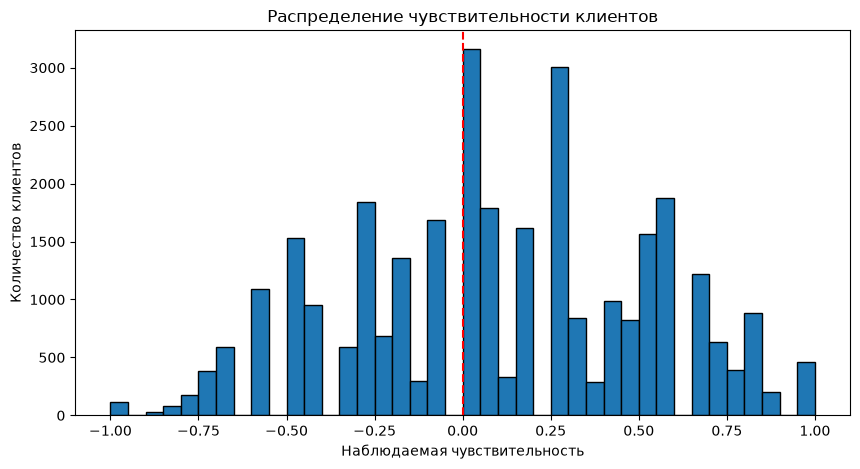

In [704]:
valid = client_summary['чувствительность'].dropna()

print('Положительная чувствительность:', (valid > 0).sum())
print('Отрицательная чувствительность:', (valid < 0).sum())
print('Нулевая чувствительность:', (valid == 0).sum())

print('Доля положительной чувствительности:', round((valid > 0).mean(), 3))
print('Доля отрицательной чувствительности:', round((valid < 0).mean(), 3))
print('Доля нулевой чувствительности:', round((valid == 0).mean(), 3))

plt.figure(figsize=(10, 5))
plt.hist(valid, bins=40, edgecolor='black')
plt.axvline(0, color='red', linestyle='--')
plt.xlabel('Наблюдаемая чувствительность')
plt.ylabel('Количество клиентов')
plt.title('Распределение чувствительности клиентов')
plt.show()

In [705]:
client_volume = client_df.groupby('Клиент')['Объём'].agg(['sum', 'mean', 'std'])
client_volume.columns = ['Общий объём', 'Средний объём', 'Стандартное отклонение']

client_summary = client_summary.join(client_volume)

client_summary[['чувствительность', 'Общий объём', 'Средний объём']].describe()

,чувствительность,Общий объём,Средний объём
count,31470.000000,33146.000000,33146.000000
mean,0.100145,901.801199,100.200133
std,0.426393,1002.890091,111.432232
min,-1.000000,50.350000,5.594444
25%,-0.250000,414.012500,46.001389
50%,0.066667,671.180000,74.575556
75%,0.466667,1085.975000,120.663889
max,1.000000,39862.070000,4429.118889


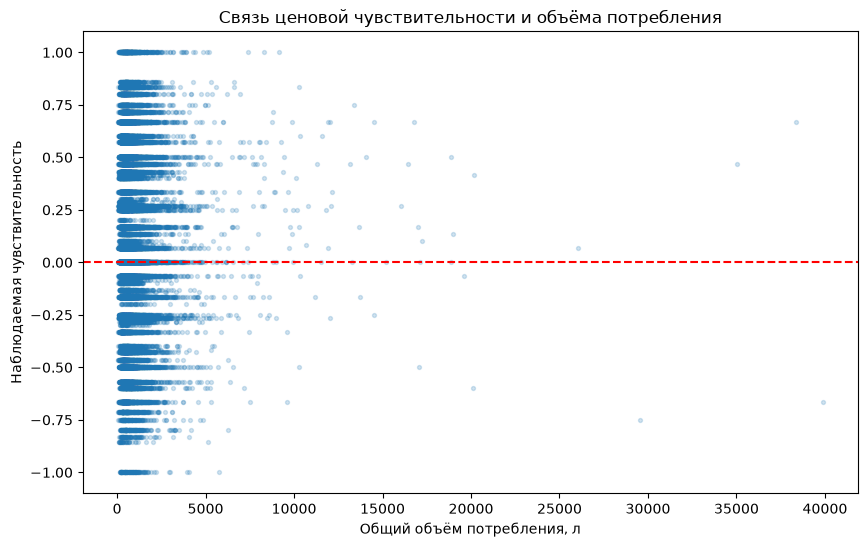

In [706]:
data = client_summary.dropna(subset=['чувствительность', 'Общий объём'])
plt.figure(figsize=(10, 6))
plt.scatter(data['Общий объём'], data['чувствительность'], alpha=0.2, s=8)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Общий объём потребления, л')
plt.ylabel('Наблюдаемая чувствительность')
plt.title('Связь ценовой чувствительности и объёма потребления')
plt.show()

просто заметка: мы можем взять порог высокой чувствительности и клиентов с объёмом например больше 5000 и для них применять какую то стратегию 

In [707]:
data = client_summary.dropna(subset=['чувствительность', 'Общий объём']).copy()

data['Группа'] = np.select(
    [data['чувствительность'] > 0, data['чувствительность'] < 0],
    ['Положительная', 'Отрицательная'],
    default='Нулевая'
)

volume_summary = data.groupby('Группа')['Общий объём'].agg(['count', 'mean', 'median'])
volume_summary.round(2)

,count,mean,median
Группа,,,
Нулевая,3164,906.31,690.96
Отрицательная,11411,912.18,686.10
Положительная,16895,892.23,655.34


чисто визуально вообще не прослеживается какой либо связи, большой объём заправок наблюдается как у чувствительных клиентов, так и у мало чувствительных. пока это разделение на чувствительность УСЛОВНОЕ 

после вывода статисттики тем более, различие буквально в 10 литров не больше 

### Анализ по размеру сокращений 

In [708]:
drops = client_changes[
    (client_changes['Изменение разницы цен'] > 0) &
    (client_changes['Изменение объёма, л'] < 0)
].copy()

drops['Сокращение, л'] = -drops['Изменение объёма, л']

drop_summary = drops.groupby('Клиент')['Сокращение, л'].agg(['count', 'mean', 'sum'])
drop_summary.columns = ['Число сокращений', 'Среднее сокращение, л', 'Общее сокращение, л']

client_summary = client_summary.join(drop_summary)
client_summary[['чувствительность', 'Общий объём', 'Среднее сокращение, л']].describe()

,чувствительность,Общий объём,"Среднее сокращение, л"
count,31470.000000,33146.000000,32432.000000
mean,0.100145,901.801199,58.137329
std,0.426393,1002.890091,81.724629
min,-1.000000,50.350000,0.010000
25%,-0.250000,414.012500,25.860000
50%,0.066667,671.180000,41.563333
75%,0.466667,1085.975000,67.158333
max,1.000000,39862.070000,3084.130000


In [709]:
client_comparable = client_changes.dropna(subset=['Изменение разницы цен', 'Изменение log(1 + объём)']).copy()

client_comparable['Цена ухудшилась'] = client_comparable['Изменение разницы цен'] > 0
client_comparable['Цена улучшилась'] = client_comparable['Изменение разницы цен'] < 0
client_comparable['Размер сокращения'] = (-client_comparable['Изменение log(1 + объём)']).clip(lower=0)#заменяет значения меньше 0 на 0 

log_worse = client_comparable[client_comparable['Цена ухудшилась']].groupby('Клиент')['Размер сокращения'].agg(['sum', 'count'])
log_better = client_comparable[client_comparable['Цена улучшилась']].groupby('Клиент')['Размер сокращения'].agg(['sum', 'count'])

client_summary['Среднее сокращение при ухудшении'] = log_worse['sum'] / log_worse['count']
client_summary['Среднее сокращение при улучшении'] = log_better['sum'] / log_better['count']
client_summary['Чувствительность по размеру'] = client_summary['Среднее сокращение при ухудшении'] - client_summary['Среднее сокращение при улучшении']

client_summary[['чувствительность', 'Чувствительность по размеру']].head()

,чувствительность,Чувствительность по размеру
Клиент,,
ID_1,-0.571429,-0.054548
ID_10,-0.250000,1.586873
ID_100,0.428571,0.197069
ID_1000,0.333333,0.335226
ID_10000,0.416667,0.151114


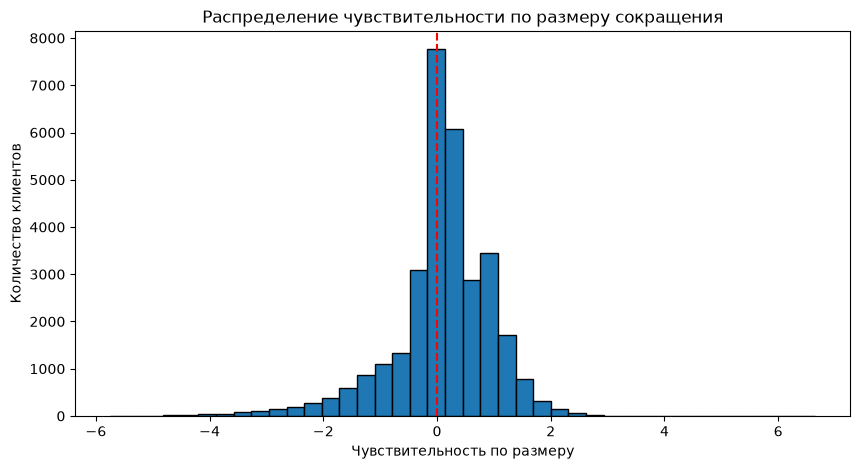

In [710]:
data = client_summary.dropna(subset=['Чувствительность по размеру'])

plt.figure(figsize=(10, 5))
plt.hist(data['Чувствительность по размеру'], bins=40, edgecolor='black')
plt.axvline(0, color='red', linestyle='--')
plt.xlabel('Чувствительность по размеру')
plt.ylabel('Количество клиентов')
plt.title('Распределение чувствительности по размеру сокращения')
plt.show()

тут уже основная масса не чувствительная, распределение смахивает на нормальное (из за лагорифма)

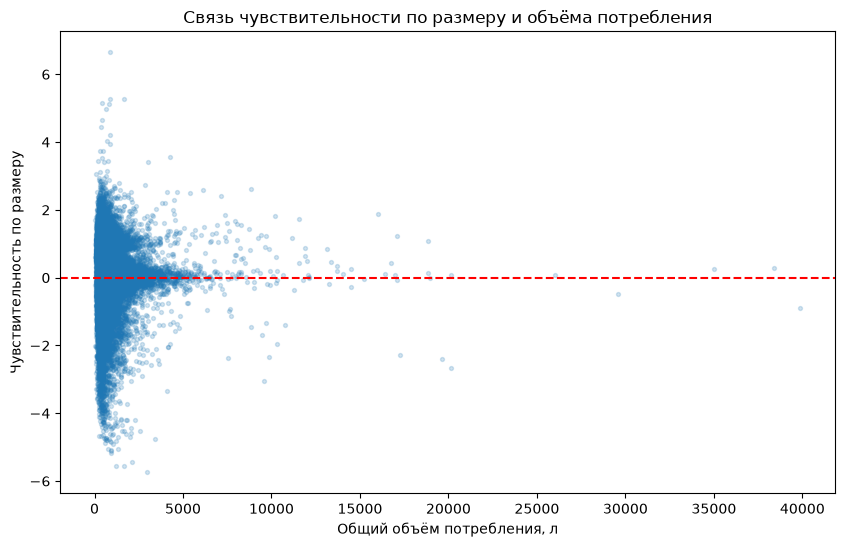

In [711]:
data = client_summary.dropna(subset=['Чувствительность по размеру', 'Общий объём'])

plt.figure(figsize=(10, 6))
plt.scatter(data['Общий объём'], data['Чувствительность по размеру'], alpha=0.2, s=8)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Общий объём потребления, л')
plt.ylabel('Чувствительность по размеру')
plt.title('Связь чувствительности по размеру и объёма потребления')
plt.show()

по факту большие объёмы потребления у нечувствительных клиентах 

In [712]:
data = client_summary.dropna(subset=['Чувствительность по размеру', 'Общий объём']).copy()
data['Группа объёма'] = pd.qcut(data['Общий объём'], q=5, labels=['Очень низкий', 'Низкий', 'Средний', 'Высокий', 'Очень высокий'])

volume_stats = data.groupby('Группа объёма', observed=True)['Чувствительность по размеру'].agg(['count', 'mean', 'median', 'std'])
volume_stats.round(3)

,count,mean,median,std
Группа объёма,,,,
Очень низкий,6294,0.147,0.338,1.051
Низкий,6295,0.109,0.224,1.012
Средний,6293,0.087,0.141,0.874
Высокий,6294,0.068,0.098,0.765
Очень высокий,6294,0.054,0.071,0.705


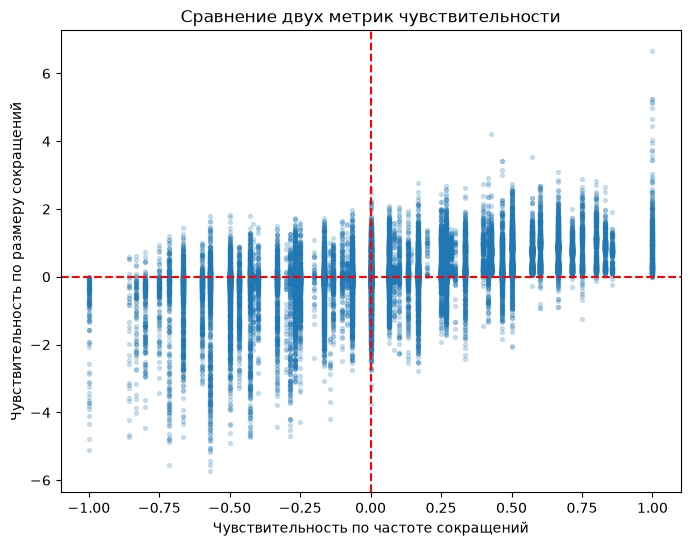

In [713]:
data = client_summary.dropna(subset=['чувствительность', 'Чувствительность по размеру'])

plt.figure(figsize=(8, 6))
plt.scatter(data['чувствительность'], data['Чувствительность по размеру'], alpha=0.2, s=8)
plt.axhline(0, color='red', linestyle='--')
plt.axvline(0, color='red', linestyle='--')
plt.xlabel('Чувствительность по частоте сокращений')
plt.ylabel('Чувствительность по размеру сокращений')
plt.title('Сравнение двух метрик чувствительности')
plt.show()

между показателями наблюдается линейная связь, 1 четверть - частые и крупные сокращения, 2 четверть -  редкие крупные, 3 четверть - редкие мелкие, 4 четверть - частые и мелкие 


первый показывает, насколько чаще клиент сокращает потребление при ухудшении относительной цены, чем при её улучшении.
второй показывает, насколько больше средняя величина сокращения потребления при ухудшении относительной цены по сравнению с её улучшением.


### Потребление за девять месяцев

In [714]:
client_consumption = client_changes.groupby('Клиент').agg(
    Общий_объём=('Объём', 'sum'),
    Среднемесячный_объём=('Объём', 'mean')
)
client_consumption['Месяцев с положительным объёмом'] = (
    (client_changes['Объём'] > 0).groupby(client_changes['Клиент']).sum()
)
client_consumption.head(20)

,Общий_объём,Среднемесячный_объём,Месяцев с положительным объёмом
Клиент,,,
ID_1,156.44,17.382222,6
ID_10,8066.04,896.226667,8
ID_100,585.05,65.005556,9
ID_1000,855.61,95.067778,9
ID_10000,838.69,93.187778,9
ID_10001,994.95,110.550000,6
ID_10002,2092.85,232.538889,9
ID_10003,309.99,34.443333,8
ID_10004,1247.85,138.650000,9


In [715]:
client_consumption[
    client_consumption['Среднемесячный_объём'] > 200
].sort_values(by='Среднемесячный_объём', ascending=False)



,Общий_объём,Среднемесячный_объём,Месяцев с положительным объёмом
Клиент,,,
ID_6098,39862.07,4429.118889,9
ID_15348,38391.54,4265.726667,9
ID_15627,35018.62,3890.957778,9
ID_32030,29567.99,3285.332222,9
ID_23484,26018.92,2890.991111,9
...,...,...,...
ID_25339,1801.68,200.186667,8
ID_6964,1801.14,200.126667,8
ID_31767,1800.82,200.091111,9


In [716]:
total_volume_stats = client_consumption['Общий_объём'].quantile([0.5, 0.9, 0.95, 0.99, 1])
total_volume_stats.index = ['Медиана', '90-й процентиль', '95-й процентиль', '99-й процентиль', 'Максимум']
total_volume_stats


Медиана              671.1800
90-й процентиль     1674.9400
95-й процентиль     2209.6325
99-й процентиль     4187.7510
Максимум           39862.0700
Name: Общий_объём, dtype: float64

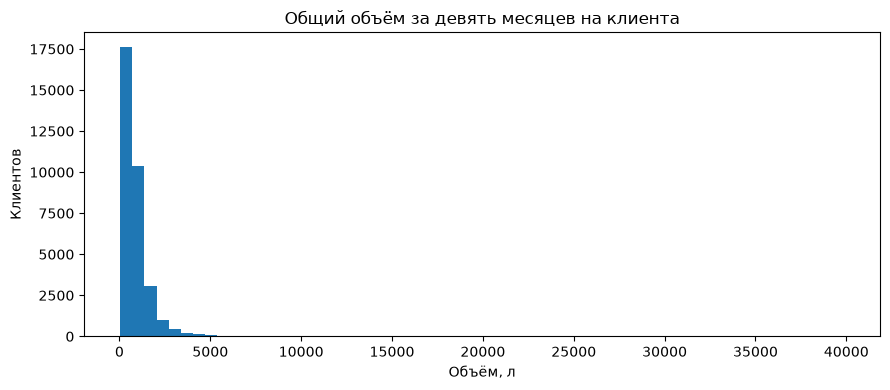

In [717]:
plt.figure(figsize=(9, 4))
plt.hist(client_consumption['Общий_объём'], bins=60)
plt.title('Общий объём за девять месяцев на клиента')
plt.xlabel('Объём, л')
plt.ylabel('Клиентов')
plt.tight_layout()
plt.show()

### Предварительное сравнение групп потребления

Клиентов с объёмом не ниже 90-го процентиля относим к исследовательской группе верхних 10%. Совпадения на границе включаем в эту группу. Это не окончательная сегментация и не метка чувствительности.

In [718]:
top_volume_threshold = client_consumption['Общий_объём'].quantile(0.9)
client_consumption['Группа потребления'] = 'Остальные'
client_consumption.loc[
    client_consumption['Общий_объём'] >= top_volume_threshold, 'Группа потребления'
] = 'Верхние 10% по объёму'
print('Граница верхней группы, л:', top_volume_threshold)
consumption_group_summary = client_consumption.groupby('Группа потребления').agg(
    Клиентов=('Общий_объём', 'size'),
    Медиана_общего_объёма=('Общий_объём', 'median'),
    Средний_месячный_объём=('Среднемесячный_объём', 'mean'),
    Среднее_число_активных_месяцев=('Месяцев с положительным объёмом', 'mean')
)
consumption_group_summary['Доля клиентов'] = consumption_group_summary['Клиентов'] / len(client_consumption)
consumption_group_summary

Граница верхней группы, л: 1674.94


,Клиентов,Медиана_общего_объёма,Средний_месячный_объём,Среднее_число_активных_месяцев,Доля клиентов
Группа потребления,,,,,
Верхние 10% по объёму,3315,2209.69,313.529911,8.556863,0.100012
Остальные,29831,616.33,76.493646,7.746304,0.899988


In [719]:
grouped_transitions = client_transitions.join(
    client_consumption['Группа потребления'], on='Клиент', validate='many_to_one'
)
group_reaction_rows = []
for group_name, observations in grouped_transitions.groupby('Группа потребления'):
    for case, price_flag, volume_flag in reaction_specs:
        denominator = observations[price_flag].sum()
        count = (observations[price_flag] & observations[volume_flag]).sum()
        group_reaction_rows.append({
            'Группа потребления': group_name, 'Случай': case,
            'Количество': count, 'Соответствующих изменений цены': denominator,
            'Доля': count / denominator if denominator > 0 else np.nan
        })
group_reaction_summary = pd.DataFrame(group_reaction_rows).set_index(['Группа потребления', 'Случай'])
group_reaction_summary

Количество  \
Группа потребления    Случай                                        
Верхние 10% по объёму Цена ухудшилась, объём снизился        9348   
                      Цена улучшилась, объём вырос           4083   
                      Цена ухудшилась, объём вырос           7282   
                      Цена улучшилась, объём снизился        3744   
Остальные             Цена ухудшилась, объём снизился       83451   
                      Цена улучшилась, объём вырос          34401   
                      Цена ухудшилась, объём вырос          63754   
                      Цена улучшилась, объём снизился       31272   

                                                       Соответствующих изменений цены  \
Группа потребления    Случай                                                            
Верхние 10% по объёму Цена ухудшилась, объём снизился                           16969   
                      Цена улучшилась, объём вырос                               8053   
                      Цена ухудшилась, объём вырос                              16969   
                      Цена улучшилась, объём снизился                            8053   
Остальные             Цена ухудшилась, объём снизился                          155627   
                      Цена улучшилась, объём вырос                              71196   
                      Цена ухудшилась, объём вырос                             155627   
                      Цена улучшилась, объём снизился                           71196   

                                                           Доля  
Группа потребления    Случай                                     
Верхние 10% по объёму Цена ухудшилась, объём снизился  0.550887  
                      Цена улучшилась, объём вырос     0.507016  
                      Цена ухудшилась, объём вырос     0.429135  
                      Цена улучшилась, объём снизился  0.464920  
Остальные             Цена ухудшилась, объём снизился  0.536224  
                      Цена улучшилась, объём вырос     0.483187  
                      Цена ухудшилась, объём вырос     0.409659  
                      Цена улучшилась, объём снизился  0.439238

### Распределение изменений разницы цен

Наблюдения здесь относятся к клиентским месяцам. Одинаковое изменение цены АЗС может повторяться у нескольких клиентов; такие наблюдения не являются независимыми ценовыми событиями.

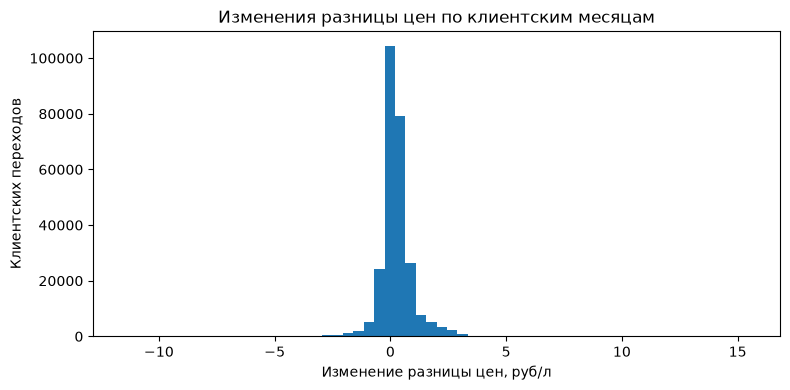

In [720]:
plt.figure(figsize=(8, 4))
plt.hist(client_transitions['Изменение разницы цен'], bins=60)
plt.title('Изменения разницы цен по клиентским месяцам')
plt.xlabel('Изменение разницы цен, руб/л')
plt.ylabel('Клиентских переходов')
plt.tight_layout()
plt.show()

## Кластеризация клиентов

In [721]:
cluster_features = [
    'чувствительность', 'Чувствительность по размеру',
    'Общий объём', 'Месяцев с положительным объёмом'
]
cluster_df = client_summary.join(client_consumption[['Месяцев с положительным объёмом']])
cluster_df = cluster_df.loc[
    (cluster_df['число_улучшений'] >= 2) &
    (cluster_df['число_ухудшений'] >= 2), cluster_features
].dropna().reset_index()

In [722]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

cluster_X = cluster_df[cluster_features].copy()
cluster_X['Общий объём'] = np.log1p(cluster_X['Общий объём'])
cluster_X = StandardScaler().fit_transform(cluster_X)
cluster_df['Кластер'] = KMeans(n_clusters=4, random_state=42, n_init=10).fit_predict(cluster_X)

In [723]:
print('Включено:', len(cluster_df), 'Исключено:', len(client_consumption) - len(cluster_df))
cluster_df.groupby('Кластер')[cluster_features].median().join(
    cluster_df['Кластер'].value_counts().rename('Клиентов')
)

Включено: 25218 Исключено: 7928


,чувствительность,Чувствительность по размеру,Общий объём,Месяцев с положительным объёмом,Клиентов
Кластер,,,,,
0,0.333333,0.206677,943.64,9.0,6614
1,0.333333,0.926620,388.77,6.0,5749
2,-0.166667,-1.037958,409.87,7.0,4314
3,-0.166667,-0.032441,889.69,9.0,8541


In [724]:
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

silhouette_indices = pd.DataFrame(cluster_X).sample(n=min(3000, len(cluster_X)), random_state=42).index.to_numpy()
kmeans_metric_rows = []

for k in range(2, 9):
    candidate_model = KMeans(n_clusters=k, random_state=42, n_init=10)
    candidate_labels = candidate_model.fit_predict(cluster_X)
    kmeans_metric_rows.append({
        'k': k,
        'Silhouette Score': silhouette_score(
            cluster_X[silhouette_indices], candidate_labels[silhouette_indices]
        ),
        'Davies–Bouldin Index': davies_bouldin_score(cluster_X, candidate_labels),
        'Calinski–Harabasz Index': calinski_harabasz_score(cluster_X, candidate_labels),
        'Inertia': candidate_model.inertia_
    })
kmeans_metrics = pd.DataFrame(kmeans_metric_rows).set_index('k')
kmeans_metrics

,Silhouette Score,Davies–Bouldin Index,Calinski–Harabasz Index,Inertia
k,,,,
2,0.299518,1.389966,10020.239318,72186.785496
3,0.324202,1.151168,10511.129741,55009.504891
4,0.255135,1.206264,9919.193601,46267.569180
5,0.234141,1.187513,8987.554235,41582.200959
6,0.239752,1.236950,8539.280917,37450.513889
7,0.234366,1.194776,8082.556032,34503.294807
8,0.231011,1.214486,7702.416580,32138.076663


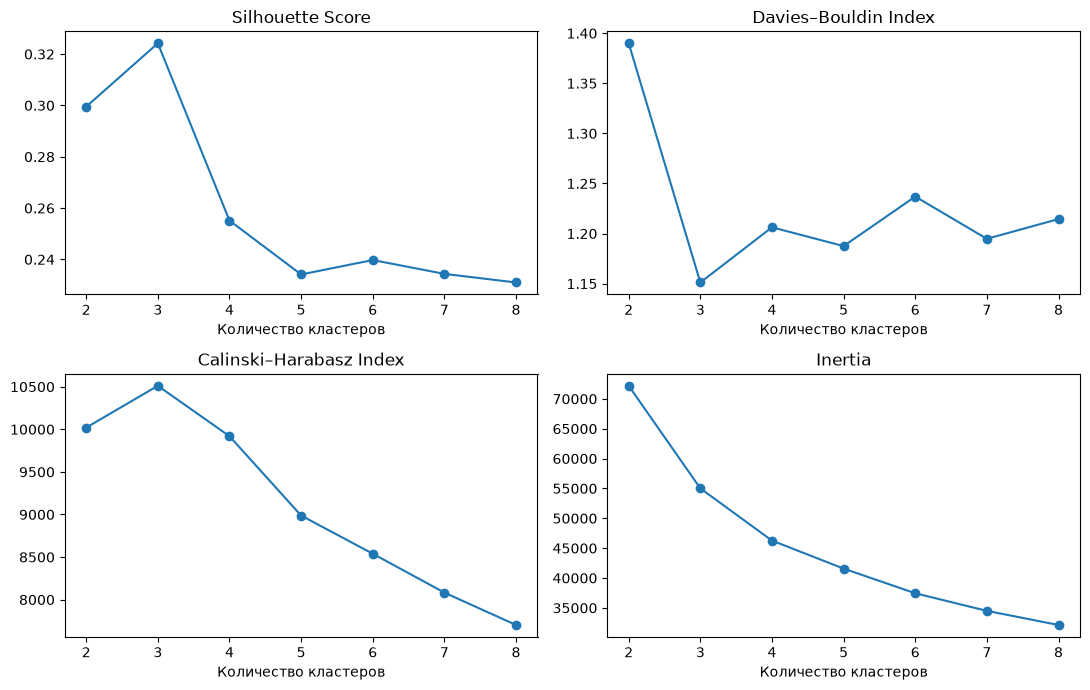

In [725]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, metric in zip(axes.flat, kmeans_metrics.columns):
    ax.plot(kmeans_metrics.index, kmeans_metrics[metric], marker='o')
    ax.set_title(metric)
    ax.set_xlabel('Количество кластеров')
    ax.set_xticks(kmeans_metrics.index)
plt.tight_layout()
plt.show()

## KMeans с тремя кластерами

In [726]:
kmeans3 = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster3_df = cluster_df[['Клиент'] + cluster_features].copy()
cluster3_df['Кластер'] = kmeans3.fit_predict(cluster_X)
cluster3_df.groupby('Кластер')[cluster_features].median().join(
    cluster3_df['Кластер'].value_counts().rename('Клиентов')
)

,чувствительность,Чувствительность по размеру,Общий объём,Месяцев с положительным объёмом,Клиентов
Кластер,,,,,
0,0.000000,0.063335,941.185,9.0,14042
1,-0.166667,-0.959376,409.180,7.0,4807
2,0.400000,0.932036,416.570,6.0,6369


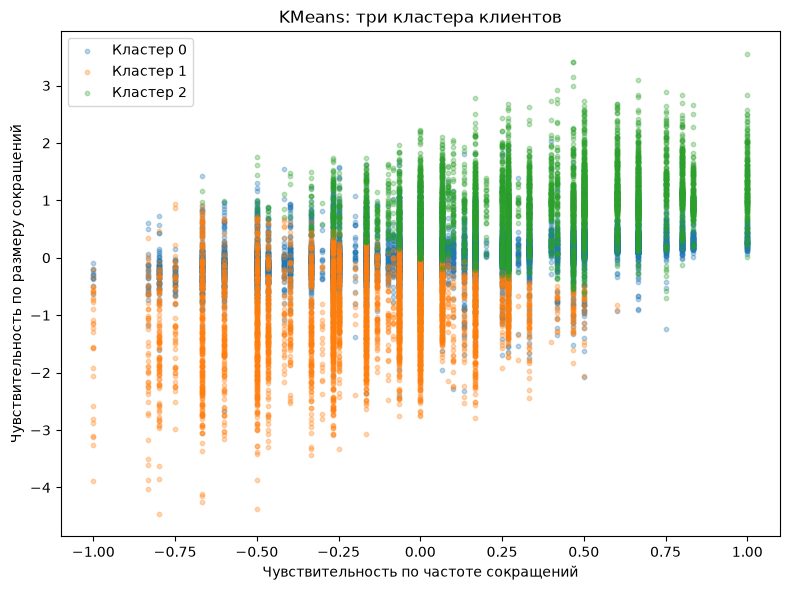

In [727]:
plt.figure(figsize=(8, 6))
for cluster, clients in cluster3_df.groupby('Кластер'):
    plt.scatter(clients['чувствительность'], clients['Чувствительность по размеру'],
                s=10, alpha=0.3, label=f'Кластер {cluster}')
plt.xlabel('Чувствительность по частоте сокращений')
plt.ylabel('Чувствительность по размеру сокращений')
plt.title('KMeans: три кластера клиентов')
plt.legend()
plt.tight_layout()
plt.show()

In [728]:
from sklearn.kernel_approximation import Nystroem

poly_sampler = Nystroem(kernel='poly', degree=2, gamma=0.25, coef0=1,
                       n_components=100, random_state=42)
poly_X = poly_sampler.fit_transform(cluster_X)
poly_kmeans3 = KMeans(n_clusters=3, n_init=10, random_state=42).fit(poly_X)
poly_labels = poly_kmeans3.labels_

In [729]:
poly_scores = pd.DataFrame({
    'Silhouette Score': [silhouette_score(
        cluster_X[silhouette_indices], poly_labels[silhouette_indices]
    )],
    'Davies–Bouldin Index': [davies_bouldin_score(cluster_X, poly_labels)]
}, index=pd.Index(['Poly + KMeans k=3'], name='Метод'))
poly_comparison = pd.concat([
    kmeans_metrics.loc[[3], poly_scores.columns].rename(index={3: 'KMeans k=3'}),
    poly_scores
]).rename_axis('Метод')
poly_comparison

,Silhouette Score,Davies–Bouldin Index
Метод,,
KMeans k=3,0.324202,1.151168
Poly + KMeans k=3,0.329422,1.121612


In [730]:
from sklearn.metrics import adjusted_rand_score

ari_kmeans_poly = adjusted_rand_score(kmeans3.labels_, poly_kmeans3.labels_)
print('Adjusted Rand Index:', ari_kmeans_poly)
# Номера кластеров двух моделей не обязаны соответствовать друг другу.
cluster_counts_comparison = pd.DataFrame({
    'KMeans k=3': pd.Series(kmeans3.labels_).value_counts(),
    'Poly + KMeans k=3': pd.Series(poly_kmeans3.labels_).value_counts()
}).sort_index().rename_axis('Кластер')
cluster_counts_comparison

Adjusted Rand Index: 0.728355692343011


,KMeans k=3,Poly + KMeans k=3
Кластер,,
0,14042,16227
1,4807,5255
2,6369,3736


In [731]:
poly_cluster_medians = cluster3_df[cluster_features].groupby(
    poly_kmeans3.labels_
).median().rename_axis('Кластер')
poly_cluster_medians

,чувствительность,Чувствительность по размеру,Общий объём,Месяцев с положительным объёмом
Кластер,,,,
0,0.000000,0.070291,868.02,9.0
1,0.466667,0.973307,390.39,6.0
2,-0.200000,-1.141148,394.73,7.0


## Оценка ценовой эластичности


In [734]:
elasticity_df = client_df.sort_values(['Клиент', 'Месяц']).copy()
elasticity_df['log_volume'] = np.log1p(elasticity_df['Объём'])
elasticity_df['log_price'] = np.log(elasticity_df['Цена Газпромнефти'] / elasticity_df['Цена конкурентов'])
elasticity_df[['dlog_volume', 'dlog_price']] = elasticity_df.groupby('Клиент')[['log_volume', 'log_price']].diff()
elasticity_transitions = elasticity_df.dropna(subset=['dlog_volume', 'dlog_price'])
elasticity_transitions[['dlog_volume', 'dlog_price']].describe()

,dlog_volume,dlog_price
count,264629.000000,264629.000000
mean,-0.093102,0.004075
std,1.659216,0.013298
min,-8.208181,-0.169276
25%,-0.494983,-0.001044
50%,-0.004233,0.002791
75%,0.366201,0.008627
max,8.279190,0.254022


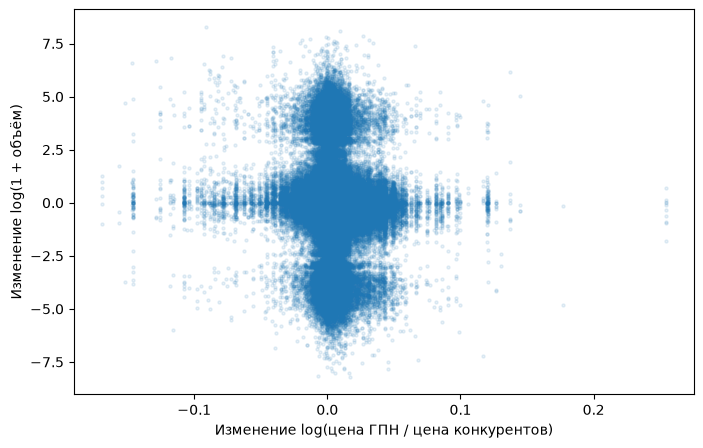

In [735]:
elasticity_transitions.plot.scatter(x='dlog_price', y='dlog_volume', s=5, alpha=0.1, figsize=(8, 5))
plt.xlabel('Изменение log(цена ГПН / цена конкурентов)')
plt.ylabel('Изменение log(1 + объём)')
plt.show()

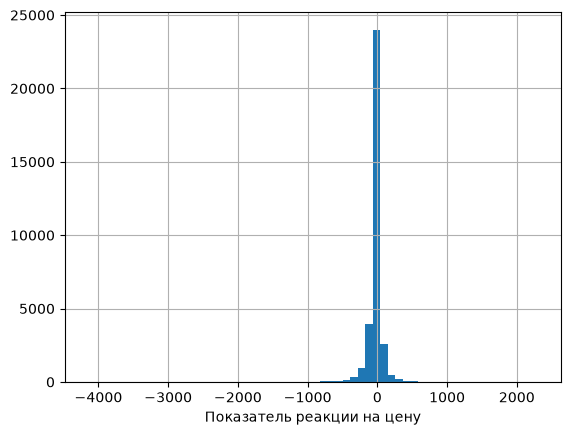

Нулевых знаменателей: 0


Сумма_квадратов_изменений_цены
0.000001      3
0.000002     24
0.000003     47
0.000003      6
0.000003      2
0.000003     20
0.000003    107
0.000003     23
0.000003     26
0.000003     43
Name: count, dtype: int64

In [738]:
elasticity_features['Реакция на цену'].hist(bins=60)
plt.xlabel('Показатель реакции на цену')
plt.show()
print('Нулевых знаменателей:', (elasticity_features['Сумма_квадратов_изменений_цены'] == 0).sum())
elasticity_features['Сумма_квадратов_изменений_цены'].value_counts().sort_index().head(10)

нужно теперь расчитать ценовую чувствительность с регуляризацией